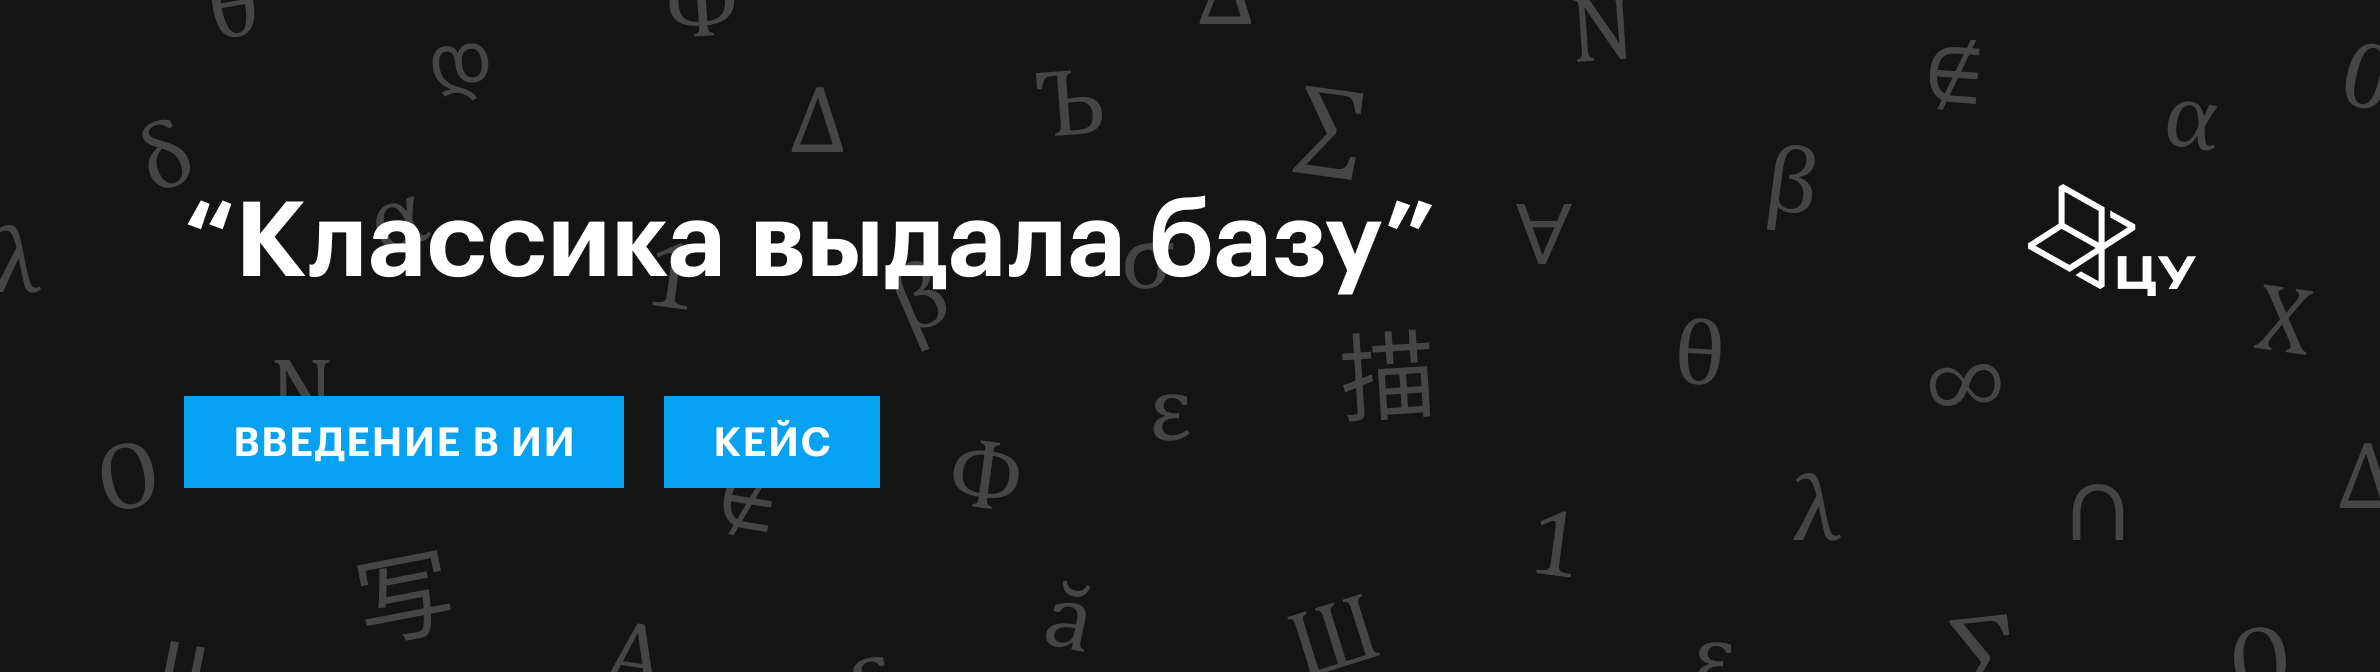

## Легенда

Представьте, что вы устроились NLP-инженером в образовательный EdTech-стартап. Маркетологи компании выяснили, что современные школьники тяжело воспринимают язык классической литературы XIX века.(Также в компанию наняли инженера, который смог встроить в каждую электронную книжкуу по экрану с Subway Surfers, чтобы ученикам было привычнее) Обилие устаревших слов, французских вставок и сложных деепричастных оборотов заставляет их «скипать» чтение.

Стартап решил запустить революционное приложение, которое будет «на лету» переводить тексты Толстого, Достоевского и Гоголя на современный интернет-сленг*.

Ваша задача: разработать нейросетевую Seq2Seq-модель, которая осуществляет перенос стиля (Text Style Transfer). Модель должна брать оригинальную реплику из классики и переписывать ее зумерским сленгом, максимально сохраняя смысл и изначальную структуру предложения.

*Примечение от автора кейса: данные по сленгу собирались из открытых источников: статей в интернете, рилсам, шортсам и тикитокам.*

## Требования к решению

Поскольку это учебный проект, вводятся следующие технические ограничения:

* **Запрет на API-читерство:** Запрещено просто прогнать тестовый датасет через API умных ЛЛМок. Вы должны самостоятельно обучить модель. *При этом, если вам хочется использовать API LLM-сервисов для обогащения датасета, аугментаций и уточнения перевода, то это не запрещено.*

* **Ограничение по размеру модели:** Решение должно корректно работать в Google Colab. Использовать несколько Google-аккаунтов для увеличения квоты на Т4 для экспериментов с архитектурой не запрещено

* **Воспроизводимость:** Весь код должен выполняться последовательно с первого раза. Обязательно фиксируйте random_seed, а также сохраняйте веса моделей и логируйте эксперимент.

**Необходимые этапы решения:**

1. Работа с датасетом. Посмотреть на статистику встречаемости слов и провести предобработку. Определиться с токенизатором и предложить простой бейзлайн.


2. Подбор архитектуры модели. Написание необходимых функций для работы с данной архитектурой. (Например, обрезка текста до 128 символов, для моделей с маленьким контекстным окном)


3. Обучение модели на датасете. Валидация метрик, подбор гиперпарметров генерации. Вспомогательные функции для генерации перевода для новых предложений (тут можно сделать функцию `def translate(text)`, которая занимается переводом текста)

**Проверяемые метрики:**

Оценка качества генерации текста — сложная задача. Мы будем использовать две метрики и смотреть на Loss модели:

*  Обучение (Train/Val Loss): Cross-Entropy Loss. Функция потерь, по которой модель обновляет веса. Желательно избежать переобучения и достичь результатов по Loss меньше ~1.5-2.0

* Главная бизнес-метрика: chrF (Character n-gram F-score). Оценивает совпадение сгенерированного текста с эталоном на уровне символов. Она идеально подходит для сленга, так как прощает ошибки в окончаниях (например, если модель выдала «кринж» вместо «кринжово»).

*  Вспомогательная метрика: BLEU-score. Классическая метрика машинного перевода. Посчитайте её для сравнения с chrF. Данная метрика легко считается и является бейзлайн-метрикой для любой задачи перевода.





## Система оценивания

Решение оценивается по трём параметрам
* **Работа с данными [4 балла]:** Оценка ставится в соответствии с тем, насколько подробно была произведена работа с данными — визуализации, предобработка и очистка/обогащение датасета будут плюсом

* **Решение задачи [4 балла]:** Оценка ставится не за итоговые метрики — для простых моделей их значение может быть небольшим, а за то, насколько качественно были проделаны эксперименты в рамках выбранной модели. То есть если в решении используется примитивная модель, получающая низкие метрики, но она обучена с разными гиперпараметрами и приёмами так, что из её качества выжимается максимум, это решение будет оценено в полный балл

* **Оформление [2 балла]:** Хочется, чтобы написанный код читался, как хорошая книга. Для этого мы добавляем баллы за оформление — они выше, если в коде появляются визуализации, комментарии к коду и сопроводительный текст, и ниже за их отсутствие

## Данные

Итоговый датасет содержит 2 колонки: chunk и translate. В столбце chunk находится кусочек текста из классики. А в столбце translate – соответствующий ему перевод.


В данном датасете вы можете найти отрывки из следующих книг / сборников / произведений:

* А. П. Чехов — Собрание сочинений (рассказы и пьесы)

* А. С. Пушкин — повесть «Пиковая дама»

* И. С. Тургенев — роман «Отцы и дети»

* М. Ю. Лермонтов — роман «Герой нашего времени»

* Н. В. Гоголь — комедия «Ревизор»

* Н. В. Гоголь — поэма «Мёртвые души»

* А. Н. Островский — Собрание пьес (включая драму «Гроза»)

* Л. Н. Толстой — роман-эпопея «Война и мир»

* Ф. М. Достоевский — роман «Братья Карамазовы»



Для подбора метода, желательно подробно исследовать датасет – можно начать с простого просмотра перевода, а закончить построение векторных представлений слов. *Главное помните, EDA должен привести вас к пониманию решения проблемы*

Ссылка на датасет: https://drive.google.com/file/d/1wn6jpF5-FeaZIo2oqSspSvbfjIiVa8F7/view

## Пояснение метрик



**BLEU-score** (Bilingual Evaluation Understudy)
Метрика основана на совпадении целых слов (униграмм) и их комбинаций (n-грамм: биграмм, триграмм и т.д.). Итоговый BLEU считается как геометрическое среднее точностей n-грамм, умноженное на штраф за краткость.

Формула:
$BLEU = BP \cdot \exp\left( \sum_{n=1}^{N} w_n \log p_n \right)$

Где:

$p_n$ — точность совпадения n-грамм (доля n-грамм из генерации, которые нашлись в эталоне).

$w_n$ — вес для $n$-граммы (обычно берут равномерные веса, например, для BLEU-4: $w_n = 0.25$).

$N$ — максимальная длина n-граммы (стандарт — 4).

$BP$ (Brevity Penalty) — штраф за краткость. Запрещает модели читерить, выдавая по одному правильному слову.

Формула штрафа за краткость ($BP$):
BP = \begin{cases} 1, & \text{если } c > r \\ \exp\left(1 - \frac{r}{c}\right), & \text{если } c \le r \end{cases}
Где $c$ — длина сгенерированного текста (candidate), $r$ — длина эталона (reference).



**chrF** (Character n-gram F-score)
В отличие от BLEU, chrF разбивает текст не на слова, а на символьные подстроки (от 1 до 6 символов) и считает по ним классическую F-меру.

Сначала считаются Precision и Recall для совпавших символьных кусочков:

$Precision (P) = \frac{\text{Кол-во совпавших символьных n-грамм}}{\text{Общее кол-во символьных n-грамм в генерации}}$


$Recall (R) = \frac{\text{Кол-во совпавших символьных n-грамм}}{\text{Общее кол-во символьных n-грамм в эталоне}}$

Затем вычисляется итоговая формула chrF (это стандартная $F_\beta$-мера):

$chrF = (1 + \beta^2) \frac{P \cdot R}{\beta^2 \cdot P + R}$

Где:

$\beta$ — параметр, определяющий баланс между точностью и полнотой.

В стандартной реализации (chrF2) используют $\beta = 2$, что дает больший вес Recall (полноте) — то есть алгоритму важнее, чтобы модель не потеряла смысл оригинала, даже если она добавила от себя лишние символы.

### Пример работы метрик

**Оригинал:** "Это было ужасно"

**Эталон**: "это было кринжово"

**Сгенерировано моделью:** "это был кринж"

----



BLEU разбивает текст по пробелам:

Слова эталона: ["это", "было", "кринжово"]

Слова модели: ["это", "был", "кринж"]

Для BLEU слова "было" и "был", а также "кринжово" и "кринж" — это абсолютно разные, никак не связанные слова (как "собака" и "самолет"). Совпало только одно слово: "это".


Шаг 1: Считаем совпадения (Precision для n-грамм)

1-граммы (отдельные слова): Из 3 сгенерированных слов в эталоне есть только одно — "это". $p_1 = 1 / 3 \approx 0.33$ (33%).

2-граммы (пары слов):
Пары модели: ["это был", "был кринж"].
Пары эталона: ["это было", "было кринжово"].
Совпадений нет! Точность $p_2 = 0 / 2 = 0$.

Шаг 2: Штраф за краткость (Brevity Penalty)
Длина генерации ($c=3$) равна длине эталона ($r=3$), поэтому модель не штрафуется за обрывание текста. $BP = 1$

Шаг 3: Итоговая формула BLEU

$$BLEU = BP \cdot \exp\left( \frac{1}{2} \log p_1 + \frac{1}{2} \log p_2 \right)$$

Так как точность биграмм $p_2 = 0$, логарифм нуля уходит в минус бесконечность, и весь BLEU обнуляется.

$$BLEU = 0$$

- - -

chrF нарезает текст на куски (например, по 4 символа, включая пробелы):

Куски эталона (14 штук):
"это_", "то_б", "о_бы", "_был", "было", "ыло_", "ло_к", "о_кр", "_кри", "крин", "ринж", "инжо", "нжов", "жово"

Куски модели (10 штук):
"это_", "то_б", "о_бы", "_был", "был_", "ыл_к", "л_кр", "_кри", "крин", "ринж"

Шаг 1: Ищем совпадения
Алгоритм сравнивает два списка и находит 7 идеальных совпадений:
"это_", "то_б", "о_бы", "_был", "_кри", "крин", "ринж". Корень слова и начало предложения схвачены верно!

Алгоритм видит, что куски "это ", "то б", " был", " кри", "крин", "ринж" совпали


Шаг 2: Считаем Точность (Precision) и Полноту (Recall)

Precision ($P$): Доля правильных кусков среди всех сгенерированных.
$P = 7 / 10 = 0.70$ (70% того, что выдала модель — верно).

Recall ($R$): Доля кусков эталона, которые смогла покрыть модель.
$R = 7 / 14 = 0.50$ (Модель восстановила 50% от оригинальной строки).

Шаг 3: Итоговая формула (F2-score)
chrF по умолчанию использует $\beta = 2$, что дает Полноте в 2 раза больший вес, чем Точности (важнее не потерять смысл, чем не наделать опечаток).

$$chrF = 5 \frac{P \cdot R}{4p+R}$$

Подставляем наши числа и получаем ответ:

$$chrF = 5 \frac{0.7 \cdot 0.5}{4\cdot 0.7 + 0.5} \approx 0.53$$

### Код метрик

Ниже уже реализованы функции подсчёта метрик. Тебе необходимо лишь использовать их

In [3]:
import math
from collections import Counter

def get_word_ngrams(tokens: list, n: int) -> list:
    """
    Разбивает список токенов на n-граммы уровня слов.
    """
    return [tuple(tokens[i : i + n]) for i in range(len(tokens) - n + 1)]


def get_char_ngrams(text: str, n: int) -> list:
    """
    Разбивает строку на n-граммы уровня символов.
    """
    return [text[i : i + n] for i in range(len(text) - n + 1)]


Покажем как работает базовое разбиение на n-граммы: посимвольные и по-"подсловные".

In [4]:
get_word_ngrams(["я", "тебя", "крашу", "чееел"], 2)

[('я', 'тебя'), ('тебя', 'крашу'), ('крашу', 'чееел')]

In [5]:
get_char_ngrams("кринж", 3)

['кри', 'рин', 'инж']

Вычислим теперь наши метрики для двух наших текстов

In [6]:
def bleu_single(reference: str, candidate: str, max_n: int = 4) -> float:
    """
    Вычисляет BLEU-score для одной пары (reference, candidate).
    Шаги:
      1. Токенизация — разбиение по пробелам
      2. Clipped precision — для каждого n считаем долю n-грамм генерации,
         которые есть в эталоне; одна n-грамма эталона не засчитывается дважды
      3. Add-1 сглаживание — (matches + 1) / (total + 1), чтобы избежать log(0)
         при нулевых совпадениях в высших n-граммах
      4. Brevity Penalty — штраф exp(1 - r/c), если генерация короче эталона

    Args:
        reference : эталонный текст (строка)
        candidate : сгенерированный текст (строка)
        max_n     : максимальный порядок n-граммы (по умолчанию 4 → BLEU-4)

    Returns:
        float в диапазоне [0.0, 1.0]
    """
    ref_tokens  = reference.lower().split()
    cand_tokens = candidate.lower().split()

    c = len(cand_tokens)
    r = len(ref_tokens)

    if c == 0:
        return 0.0

    # Штрафуем только за генерацию короче эталона; длиннее — штрафа нет
    bp  = 1.0 if c > r else math.exp(1 - r / c)
    w_n = 1.0 / max_n
    log_avg = 0.0

    for n in range(1, max_n + 1):
        ref_ngrams  = Counter(get_word_ngrams(ref_tokens, n))
        cand_ngrams = Counter(get_word_ngrams(cand_tokens, n))

        # Clipped: не даём модели накручивать счёт повторами одной n-граммы
        matches = sum(min(cnt, ref_ngrams[ngram]) for ngram, cnt in cand_ngrams.items())
        total   = max(c - n + 1, 1)  # floor=1, если предложение короче n

        # Нет совпадений даже на уровне слов — тексты семантически разные
        if n == 1 and matches == 0:
            return 0.0

        p_n      = (matches + 1) / (total + 1)
        log_avg += w_n * math.log(p_n)

    return bp * math.exp(log_avg)


def chrf_single(reference: str, candidate: str, max_n: int = 6, beta: float = 2.0) -> float:
    """
    Вычисляет chrF-score для одной пары (reference, candidate).

    Шаги:
      1. Разбить оба текста на символьные n-граммы (для n от 1 до max_n)
      2. Для каждого n посчитать Precision и Recall по совпавшим кускам
      3. Усреднить Precision и Recall по всем n
      4. Итог: F_beta-мера из усредненных P и R

    Args:
        reference  : эталонный текст (строка)
        candidate  : сгенерированный текст (строка)
        max_n      : максимальный порядок символьной n-граммы (по умолчанию 6)
        beta       : вес Recall относительно Precision (по умолчанию 2.0 -> chrF2)

    Returns:
        float в диапазоне [0.0, 1.0]
    """
    if len(candidate) == 0 or len(reference) == 0:
        return 0.0

    total_precision = 0.0
    total_recall    = 0.0

    for n in range(1, max_n + 1):
        ref_ngrams  = Counter(get_char_ngrams(reference, n))
        cand_ngrams = Counter(get_char_ngrams(candidate, n))

        # Считаем совпавшие символьные куски
        matches = sum(
            min(count, ref_ngrams.get(ngram, 0))
            for ngram, count in cand_ngrams.items()
        )

        total_cand = sum(cand_ngrams.values())  # знаменатель Precision
        total_ref  = sum(ref_ngrams.values())   # знаменатель Recall

        if total_cand > 0:
            total_precision += (matches + 1)/ (total_cand + 1)
        if total_ref > 0:
            total_recall += matches / total_ref

    # Усредняем Precision и Recall по всем порядкам n
    avg_p = total_precision / max_n
    avg_r = total_recall    / max_n

    if avg_p + avg_r == 0:
        return 0.0

    # считаем f-бета меру
    chrf = (1 + beta**2) * (avg_p * avg_r) / (beta**2 * avg_p + avg_r)
    return chrf




А теперь с помощью функций выше напишем вычисление метрик для массива текстов. Мы используем такой же интерфейс как у `sci-kit-learn`, где есть необходимо передать `y_true` и `y_pred`

In [7]:
def compute_bleu(y_true: list, y_pred: list, max_n: int = 4) -> float:
    """Считает средний BLEU по всем парам датасета."""
    scores = [bleu_single(ref, cand, max_n) for ref, cand in zip(y_true, y_pred)]
    return sum(scores) / len(scores)


def compute_chrf(y_true: list, y_pred: list, max_n: int = 6, beta: float = 2.0) -> float:
    """Считает средний chrF по всем парам датасета."""
    scores = [chrf_single(ref, cand, max_n, beta) for ref, cand in zip(y_true, y_pred)]
    return sum(scores) / len(scores)


А здесь мы посмотрим на примеры работы этих метрик с помощью assert-ов

In [8]:

# ──────────────── ТЕСТ 1 ────────────────
# Идеальное совпадение: предсказание == эталон
# Ожидание: BLEU = 1.0, chrF = 1.0
ref = "этот анк выдал жесткую базу"
assert bleu_single(ref, ref) == 1.0, \
    "ТЕСТ 1 BLEU: При идеальном совпадении BLEU должен быть 1.0"
assert abs(chrf_single(ref, ref) - 1.0) < 1e-9, \
    " ТЕСТ 1 chrF: При идеальном совпадении chrF должен быть 1.0"
print("Тест 1 пройден: Идеальное совпадение → BLEU=1.0, chrF=1.0")

# ──────────────── ТЕСТ 2 ────────────────
# Пустая генерация: candidate = ""
# Ожидание: BLEU = 0.0, chrF = 0.0
ref = "он буквально вкрашился в неё"
assert bleu_single(ref, "") == 0.0, \
    " ТЕСТ 2 BLEU: Пустая генерация должна давать 0.0"
assert chrf_single(ref, "") == 0.0, \
    " ТЕСТ 2 chrF: Пустая генерация должна давать 0.0"
print("Тест 2 пройден: Пустая генерация → BLEU=0.0, chrF=0.0")

# ──────────────── ТЕСТ 3 ────────────────
# Полностью разные тексты
# Ожидание: BLEU = 0.0, chrF близко к 0
ref  = "служить бы рад прислуживаться тошно"
cand = "икс игрек зет фу бар"
assert bleu_single(ref, cand) == 0.0, \
    " ТЕСТ 3 BLEU: Полностью разные тексты → BLEU должен быть 0.0"
assert chrf_single(ref, cand) < 0.1, \
    " ТЕСТ 3 chrF: Полностью разные тексты → chrF должен быть близок к 0"
print(" Тест 3 пройден: Полностью разные тексты → BLEU=0.0, chrF≈0")

# ──────────────── ТЕСТ 4 ────────────────
# Ключевой тест: chrF > BLEU при морфологическом совпадении
# "кринж" vs "кринжово" — разные слова для BLEU, но похожие символьно для chrF
ref  = "это было кринжово"
cand = "это было кринж"
bleu_score = bleu_single(ref, cand)
chrf_score = chrf_single(ref, cand)
assert chrf_score > bleu_score, \
    f" ТЕСТ 4: chrF ({chrf_score:.3f}) должен быть > BLEU ({bleu_score:.3f}) при морфологических различиях!"
print(f" Тест 4 пройден: chrF ({chrf_score:.3f}) > BLEU ({bleu_score:.3f}) — chrF лучше для русской морфологии!")

# ──────────────── ТЕСТ 5 ────────────────
# Частичное совпадение: значения должны быть строго в диапазоне (0, 1)
ref  = "базаров выдал жесткую базу и ливнул"
cand = "базаров выдал базу и просто ушел"
bleu_score = bleu_single(ref, cand)
chrf_score = chrf_single(ref, cand)
assert 0.0 < bleu_score < 1.0, \
    f" ТЕСТ 5 BLEU: При частичном совпадении BLEU должен быть в (0, 1), получили {bleu_score:.3f}"
assert 0.0 < chrf_score < 1.0, \
    f" ТЕСТ 5 chrF: При частичном совпадении chrF должен быть в (0, 1), получили {chrf_score:.3f}"
print(f" Тест 5 пройден: Частичное совпадение → BLEU={bleu_score:.3f}, chrF={chrf_score:.3f}")

# ──────────────── ТЕСТ 6 ────────────────
# Тест усреднения по датасету
y_true = ["этот скуф выдал базу",     "она ливнула с вписки"]
y_pred = ["этот скуф выдал базу",     "она ливнула с вписки"]  # идеальные предсказания
assert compute_bleu(y_true, y_pred) == 1.0, \
    " ТЕСТ 6 BLEU: Усредненный BLEU по идеальным парам должен быть 1.0"
assert abs(compute_chrf(y_true, y_pred) - 1.0) < 1e-9, \
    " ТЕСТ 6 chrF: Усредненный chrF по идеальным парам должен быть 1.0"
print(" Тест 6 пройден: Усреднение по датасету работает корректно!")


Тест 1 пройден: Идеальное совпадение → BLEU=1.0, chrF=1.0
Тест 2 пройден: Пустая генерация → BLEU=0.0, chrF=0.0
 Тест 3 пройден: Полностью разные тексты → BLEU=0.0, chrF≈0
 Тест 4 пройден: chrF (0.825) > BLEU (0.595) — chrF лучше для русской морфологии!
 Тест 5 пройден: Частичное совпадение → BLEU=0.366, chrF=0.560
 Тест 6 пройден: Усреднение по датасету работает корректно!


## Пример работы метрик

**Оригинал:** "Это было ужасно".

**Эталон**: "это было кринжово"

**Сгенерировано моделью:** "это был кринж"




----



BLEU разбивает текст по пробелам:

Слова эталона: ["это", "было", "кринжово"]

Слова модели: ["это", "был", "кринж"]

Для BLEU слова "было" и "был", а также "кринжово" и "кринж" — это абсолютно разные, никак не связанные слова (как "собака" и "самолет"). Совпало только одно слово: "это".


Шаг 1: Считаем совпадения (Precision для n-грамм)

1-граммы (отдельные слова): Из 3 сгенерированных слов в эталоне есть только одно — "это". $p_1 = 1 / 3 \approx 0.33$ (33%).

2-граммы (пары слов):
Пары модели: ["это был", "был кринж"].
Пары эталона: ["это было", "было кринжово"].
Совпадений нет! Точность $p_2 = 0 / 2 = 0$.

Шаг 2: Штраф за краткость (Brevity Penalty)
Длина генерации ($c=3$) равна длине эталона ($r=3$), поэтому модель не штрафуется за обрывание текста. $BP = 1$

Шаг 3: Итоговая формула BLEU

$$BLEU = BP \cdot \exp\left( \frac{1}{2} \log p_1 + \frac{1}{2} \log p_2 \right)$$

Так как точность биграмм $p_2 = 0$, логарифм нуля уходит в минус бесконечность, и весь BLEU обнуляется.

$$BLEU = 0$$

- - -

chrF нарезает текст на куски (например, по 4 символа, включая пробелы):

Куски эталона (14 штук):
"это_", "то_б", "о_бы", "_был", "было", "ыло_", "ло_к", "о_кр", "_кри", "крин", "ринж", "инжо", "нжов", "жово"

Куски модели (10 штук):
"это_", "то_б", "о_бы", "_был", "был_", "ыл_к", "л_кр", "_кри", "крин", "ринж"

Шаг 1: Ищем совпадения
Алгоритм сравнивает два списка и находит 7 идеальных совпадений:
"это_", "то_б", "о_бы", "_был", "_кри", "крин", "ринж". Корень слова и начало предложения схвачены верно!

Алгоритм видит, что куски "это ", "то б", " был", " кри", "крин", "ринж" совпали


Шаг 2: Считаем Точность (Precision) и Полноту (Recall)

Precision ($P$): Доля правильных кусков среди всех сгенерированных.
$P = 7 / 10 = 0.70$ (70% того, что выдала модель — верно).

Recall ($R$): Доля кусков эталона, которые смогла покрыть модель.
$R = 7 / 14 = 0.50$ (Модель восстановила 50% от оригинальной строки).

Шаг 3: Итоговая формула (F2-score)
chrF по умолчанию использует $\beta = 2$, что дает Полноте в 2 раза больший вес, чем Точности (важнее не потерять смысл, чем не наделать опечаток).

$$chrF = 5 \frac{P \cdot R}{4p+R}$$

Подставляем наши числа и получаем ответ:

$$chrF = 5 \frac{0.7 \cdot 0.5}{4\cdot 0.7 + 0.5} \approx 0.53$$

Здесь вам надо будет реализовать функции подсчета метрик для двух текстов

Зависимости устанавливаются один раз из `requirements.txt` перед запуском ноутбука.

In [10]:
# import sacrebleu
#
# def bleu_single(reference: str, candidate: str, max_n: int = 4) -> float:
#     """
#     BLEU для одной пары (sentence-level) через sacrebleu.
#     Возвращает значение в диапазоне [0, 1].
#     """
#     if not candidate.strip():
#         return 0.0
#
#     bleu = sacrebleu.sentence_bleu(
#         candidate,
#         [reference],
#         smooth_method="none",
#         use_effective_order=False
#     )
#     return bleu.score / 100.0
#
#
# def chrf_single(reference: str, candidate: str, max_n: int = 6, beta: float = 2.0) -> float:
#     """
#     chrF для одной пары (sentence-level) через sacrebleu.
#     Возвращает значение в диапазоне [0, 1].
#     """
#     if not candidate.strip():
#         return 0.0
#
#     chrf = sacrebleu.sentence_chrf(
#         candidate,
#         [reference],
#         char_order=4,
#         beta=beta
#     )
#     return chrf.score / 100.0
#
#
# def compute_bleu(y_true: list, y_pred: list, max_n: int = 4) -> float:
#     """
#     Corpus-level BLEU через sacrebleu (корректный стандартный способ).
#     Возвращает значение в диапазоне [0, 1].
#     """
#     if not y_true:
#         return 0.0
#
#     bleu = sacrebleu.corpus_bleu(
#         y_pred,
#         [y_true],
#         smooth_method="none",
#         use_effective_order=False
#     )
#     return bleu.score / 100.0
#
#
# def compute_chrf(y_true: list, y_pred: list, max_n: int = 6, beta: float = 2.0) -> float:
#     """
#     Corpus-level chrF через sacrebleu.
#     Возвращает значение в диапазоне [0, 1].
#     """
#     if not y_true:
#         return 0.0
#
#     chrf = sacrebleu.corpus_chrf(
#         y_pred,
#         [y_true],
#         char_order=max_n,
#         beta=beta
#     )
#     return chrf.score / 100.0

In [11]:
bleu_single("это было кринжово", "это было кринж")
chrf_single("это было кринжово", "это было кринж")

0.8247762218711755

Тесты. Их необходимо запустить, и если они сработают верно – продолжать дальше

In [12]:
# ──────────────── ТЕСТ 1 ────────────────
ref = "этот анк выдал жесткую базу"
assert bleu_single(ref, ref) == 1.0, \
    "❌ ТЕСТ 1 BLEU: При идеальном совпадении BLEU должен быть 1.0"
assert abs(chrf_single(ref, ref) - 1.0) < 1e-9, \
    "❌ ТЕСТ 1 chrF: При идеальном совпадении chrF должен быть 1.0"
print("✅ Тест 1 пройден")

# ──────────────── ТЕСТ 2 ────────────────
ref = "он буквально вкрашился в неё"
assert bleu_single(ref, "") == 0.0, \
    "❌ ТЕСТ 2 BLEU: Пустая генерация должна давать 0.0"
assert chrf_single(ref, "") == 0.0, \
    "❌ ТЕСТ 2 chrF: Пустая генерация должна давать 0.0"
print("✅ Тест 2 пройден")

# ──────────────── ТЕСТ 3 ────────────────
ref  = "служить бы рад прислуживаться тошно"
cand = "икс игрек зет фу бар"
assert bleu_single(ref, cand) == 0.0, \
    "❌ ТЕСТ 3 BLEU: Полностью разные тексты => BLEU должен быть 0.0"
assert chrf_single(ref, cand) < 0.1, \
    "❌ ТЕСТ 3 chrF: Полностью разные тексты => chrF должен быть близок к 0"
print("✅ Тест 3 пройден")

# ──────────────── ТЕСТ 4 ────────────────
ref  = "это было кринжово"
cand = "это было кринж"
bleu_score = bleu_single(ref, cand)
chrf_score = chrf_single(ref, cand)
assert chrf_score > bleu_score, \
    f"❌ ТЕСТ 4: chrF ({chrf_score:.3f}) должен быть > BLEU ({bleu_score:.3f}) при морфологических различиях!"
print(f"✅ Тест 4 пройден")

# ──────────────── ТЕСТ 5 ────────────────
ref  = "базаров выдал жесткую базу и ливнул"
cand = "базаров выдал базу и просто ушел"
bleu_score = bleu_single(ref, cand)
chrf_score = chrf_single(ref, cand)
assert 0.0 < bleu_score < 1.0, \
    f"❌ ТЕСТ 5 BLEU: При частичном совпадении BLEU должен быть в (0, 1), получили {bleu_score:.3f}"
assert 0.0 < chrf_score < 1.0, \
    f"❌ ТЕСТ 5 chrF: При частичном совпадении chrF должен быть в (0, 1), получили {chrf_score:.3f}"
print(f"✅ Тест 5 пройден")

# ──────────────── ТЕСТ 6 ────────────────
y_true = ["этот скуф выдал базу",     "она ливнула с вписки"]
y_pred = ["этот скуф выдал базу",     "она ливнула с вписки"]  #
assert compute_bleu(y_true, y_pred) == 1.0, \
    "❌ ТЕСТ 6 BLEU: Усредненный BLEU по идеальным парам должен быть 1.0"
assert abs(compute_chrf(y_true, y_pred) - 1.0) < 1e-9, \
    "❌ ТЕСТ 6 chrF: Усредненный chrF по идеальным парам должен быть 1.0"
print("✅ Тест 6 пройден")

print("\n🎉 Все 6 тестов пройдены! Ваши реализации метрик корректны.")

✅ Тест 1 пройден
✅ Тест 2 пройден
✅ Тест 3 пройден
✅ Тест 4 пройден
✅ Тест 5 пройден
✅ Тест 6 пройден

🎉 Все 6 тестов пройдены! Ваши реализации метрик корректны.


## Попытка 1

### Импорты

In [13]:
import pandas as pd
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

### Загрузка и предобработка данных

In [14]:
url = (
    "https://drive.google.com/uc?export=download"
    "&id=1wn6jpF5-FeaZIo2oqSspSvbfjIiVa8F7"
)

df = pd.read_csv(
    url,
    encoding="utf-8",
    dtype=str,
    keep_default_na=False,
)

print("Всего пар:", len(df))
print("Пустых оригиналов:", df["chunk"].str.strip().eq("").sum())
print("Пустых переводов:", df["translate"].str.strip().eq("").sum())
print("Дубликатов пар:", df.duplicated().sum())

for index, row in df.sample(2, random_state=42).iterrows():
    print(f"\nПара {index}")
    print("ОРИГИНАЛ:\n", row["chunk"])
    print("\nПЕРЕВОД:\n", row["translate"])

Всего пар: 3624
Пустых оригиналов: 0
Пустых переводов: 11
Дубликатов пар: 0

Пара 605
ОРИГИНАЛ:
 (МАЛЕНЬКОЕ НЕДОРАЗУМЕНИЕ)
    
     - Чучело ты, чучело! Образина ты лысая! -
говорила однажды Пелагея Петровна своему супругу,
отставному коллежскому секретарю Маркелу
Ивановичу Лохматову. - У всех мужья как мужья,
одну только меня господь наказал
сокровищем-лежебоком! У сестры Глашеньки муж и
носки штопает, и кур кормит, и за провизией на рынок
ходит. Прасковьи Ивановнин муж, и что это за человек!
- только и ищет, чем бы жене своей угодить: то клопов
из кроватей вываривает, то шубу выбивает, чтоб моль
не поела, то рыбу чистит. Один только ты у меня,
нечистый тебя знает, в кого уродился! День-деньской
лежишь, как анафема, на диване и только и знаешь, что
водку трескаешь да про Румелию балясы точишь!..
     - Что же мне делать? - робко спросил Маркел
Иваныч.
     - Что делать! Да мало ли делов? Куда в хозяйстве
ни сунься, везде дело. Взять хоть индейского петуха. Уж
неделя, как тварь не пье

In [15]:
def clean_text(text):
    text = text.replace("\xa0", " ")
    text = re.sub(r"(?m)^[ \t]*\{\d+\}[ \t]*$", "", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

df_clean = df.copy()

for column in ["chunk", "translate"]:
    df_clean[column] = df_clean[column].map(clean_text)

valid = (
    df_clean["chunk"].ne("")
    & df_clean["translate"].ne("")
)
df_clean = df_clean.loc[valid].copy()

print("Удалено пар:", len(df) - len(df_clean))
print("Осталось пар:", len(df_clean))

Удалено пар: 11
Осталось пар: 3613


### Пары с разной длиной перевода и оригинала

In [16]:
lengths = pd.DataFrame({
    "source_chars": df_clean["chunk"].str.len(),
    "target_chars": df_clean["translate"].str.len(),
})
lengths["ratio"] = lengths["target_chars"] / lengths["source_chars"]

sus_left = 0.7
sus_right = 1.5
suspicious = lengths.loc[
    (lengths["ratio"] < 0.7) | (lengths["ratio"] > 1.5)
].sort_values("ratio")

print("Подозрительных пар:", len(suspicious))
display(suspicious.round(2))

examples = pd.concat([
    suspicious.head(1),
    suspicious.tail(1),
])

for index in examples.index.unique():
    print(f"\nПара {index}, отношение длин: {lengths.loc[index, 'ratio']:.2f}")
    print("ОРИГИНАЛ:\n", df_clean.loc[index, "chunk"])
    print("\nПЕРЕВОД:\n", df_clean.loc[index, "translate"])

Подозрительных пар: 55


,source_chars,target_chars,ratio
2513,3142,45,0.01
944,1886,55,0.03
2238,2205,71,0.03
3134,2659,112,0.04
334,1790,128,0.07
1430,3929,298,0.08
175,720,60,0.08
1058,1516,131,0.09
2779,2495,230,0.09
3235,2443,229,0.09



Пара 2513, отношение длин: 0.01
ОРИГИНАЛ:
 Маленькая княгиня лежала на подушках, в белом чепчике (страданье только что отпустило ее), черные волосы прядями вились у ее воспаленных, вспотевших щек; румяный, прелестный ротик, с губкой, покрытой черными волосиками, был раскрыт, и она радостно улыбалась. Князь Андрей вошел в комнату и остановился перед ней, у изножья дивана, на котором она лежала. Блестящие глаза, смотревшие детски-испуганно и взволнованно, остановились на нем, не изменяя выражения. «Я вас всех люблю, я никому зла не делала, за что я страдаю? Помогите мне», – говорило ее выражение. Она видела мужа, но не понимала значения его появления теперь перед нею. Князь Андрей обошел диван и в лоб поцеловал ее.

– Душенька моя! – сказал он слово, которое никогда не говорил ей. – Бог милостив…

Она вопросительно, детски-укоризненно посмотрела на него.

«Я от тебя ждала помощи, и ничего, ничего, и ты тоже!» – сказали ее глаза. Она не удивилась, что он приехал; она не поняла того, что 

In [17]:
for index in [3329, 3004]:
    print(f"\nПара {index}, отношение длин: {lengths.loc[index, 'ratio']:.2f}")
    print("ОРИГИНАЛ:\n", df_clean.loc[index, "chunk"])
    print("\nПЕРЕВОД:\n", df_clean.loc[index, "translate"])


Пара 3329, отношение длин: 0.50
ОРИГИНАЛ:
 Нет, никогда я не могу забыть этих минут! Она начала рассказывать, она все рассказала, весь этот эпизод, поведанный Митей Алеше, и «земной поклон», и причины, и про отца своего, и появление свое у Мити, и ни словом, ни единым намеком не упомянула о том, что Митя, чрез сестру ее, сам предложил «прислать к нему Катерину Ивановну за деньгами». Это она великодушно утаила и не устыдилась выставить наружу, что это она, она сама, прибежала тогда к молодому офицеру, своим собственным порывом, надеясь на что-то… чтобы выпросить у него денег. Это было нечто потрясающее. Я холодел и дрожал слушая, зала замерла, ловя каждое слово. Тут было что-то беспримерное, так что даже и от такой самовластной и презрительно-гордой девушки, как она, почти невозможно было ожидать такого высокооткровенного показания, такой жертвы, такого самозаклания. И для чего, для кого? Чтобы спасти своего изменника и обидчика, чтобы послужить хоть чем-нибудь, хоть малым, к спасению 

In [56]:
sus_left = 0.89
sus_right = 1.10

ratio = lengths["ratio"]

def count_pairs(left, right):
    if left > right:
        raise ValueError("Левая граница должна быть не больше правой.")

    return ratio.between(left, right).sum() / df_clean.shape[0]

print("Останется пар:", count_pairs(sus_left, sus_right))

Останется пар: 0.9703847218378079


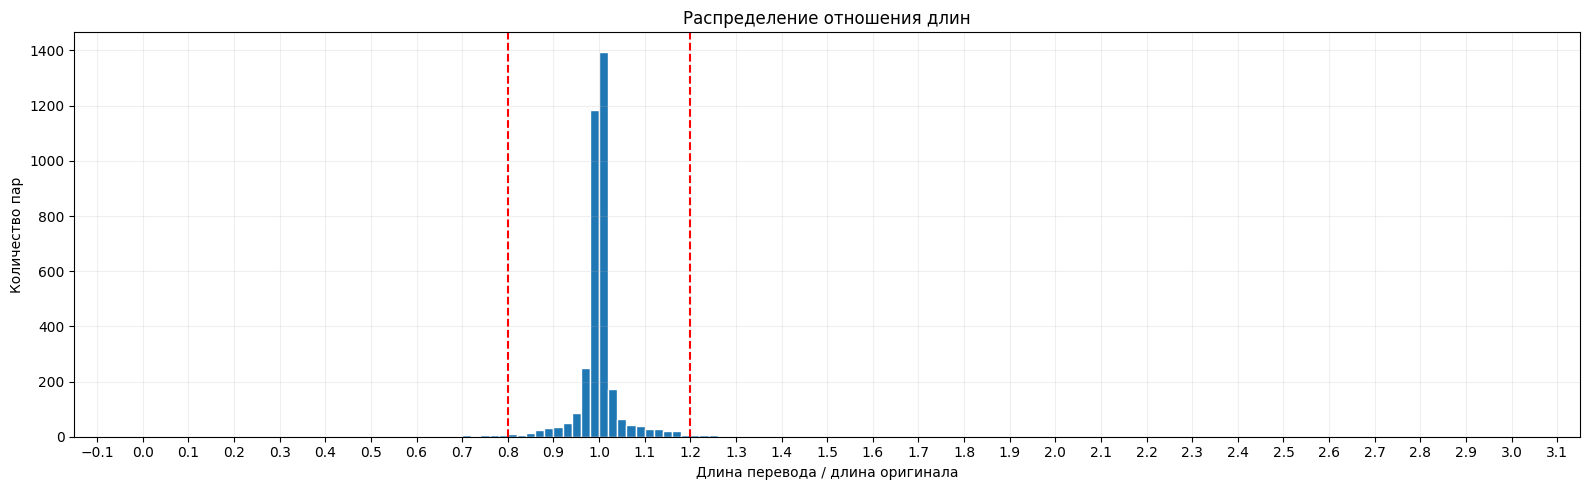

In [57]:
plt.figure(figsize=(16, 5))

plt.hist(ratio, bins=150, range=(0, 3), edgecolor="white")
plt.axvline(sus_left, color="red", linestyle="--")
plt.axvline(sus_right, color="red", linestyle="--")

plt.title("Распределение отношения длин")
plt.xlabel("Длина перевода / длина оригинала")
plt.ylabel("Количество пар")
plt.grid(axis="y", alpha=0.2)
plt.grid(axis="x", alpha=0.2)
plt.gca().xaxis.set_major_locator(MultipleLocator(0.1))

plt.tight_layout()
plt.show()

In [20]:
df_filtered = df_clean.loc[
    ratio.between(sus_left, sus_right)
].copy()

print("Удалено пар:", len(df_clean) - len(df_filtered))
print("Осталось пар:", len(df_filtered))
print(f"Сохранено: {len(df_filtered) / len(df_clean):.2%}")

Удалено пар: 278
Осталось пар: 3335
Сохранено: 92.31%


## Токенизация

### Длина кусочков

In [21]:
import tqdm as notebook_tqdm
from transformers import T5Tokenizer

C:\proga\p\pasha\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Зависимости устанавливаются один раз из `requirements.txt` перед запуском ноутбука.

In [23]:
tokenizer = T5Tokenizer.from_pretrained("cointegrated/rut5-small")

token_lengths = pd.DataFrame(index=df_filtered.index)

for column in ["chunk", "translate"]:
    encoded = tokenizer(
        df_filtered[column].tolist(),
        add_special_tokens=True,
        padding=False,
        truncation=False,
    )
    token_lengths[column] = [
        len(ids) for ids in encoded["input_ids"]
    ]

display(
    token_lengths
    .describe(percentiles=[0.5, 0.9, 0.95])
    .loc[["min", "50%", "90%", "95%", "max"]]
    .round(0)
)

for limit in [256, 512]:
    too_long = (token_lengths > limit).any(axis=1)
    print(
        f"Длиннее {limit} токенов хотя бы с одной стороны: "
        f"{too_long.sum()} из {len(token_lengths)} пар "
        f"({too_long.mean():.1%})"
    )

,chunk,translate
min,24.0,26.0
50%,857.0,856.0
90%,1247.0,1258.0
95%,1406.0,1396.0
max,7083.0,7086.0


Длиннее 256 токенов хотя бы с одной стороны: 3293 из 3335 пар (98.7%)
Длиннее 512 токенов хотя бы с одной стороны: 3036 из 3335 пар (91.0%)


In [24]:
for limit in [512, 768, 1024, 1280, 1536, 2048]:
    fits = token_lengths.le(limit).all(axis=1)

    print(
        f"Лимит {limit}: {fits.sum()} из {len(token_lengths)} пар "
        f"({fits.mean():.1%})"
    )

Лимит 512: 299 из 3335 пар (9.0%)
Лимит 768: 1451 из 3335 пар (43.5%)
Лимит 1024: 2287 из 3335 пар (68.6%)
Лимит 1280: 3017 из 3335 пар (90.5%)
Лимит 1536: 3250 из 3335 пар (97.5%)
Лимит 2048: 3303 из 3335 пар (99.0%)


1536 хватает, можно даже 1280 или 1024 если этого хватит. Разделять куски не буду - это геморрой

## Подготовка видеокарты
Писал ноутбук я в пайчарме, потом перед отправкой проверю в колабе что всё работает. Тут может остаться закомменченный код

^C


In [35]:
import torch
from tqdm import tqdm

print("PyTorch:", torch.__version__)
print("CUDA в сборке:", torch.version.cuda)
print("GPU доступен:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

    x = torch.randn(100, 100, device="cuda")
    print("Проверка вычислений:", (x @ x).device)

PyTorch: 2.11.0+cu128
CUDA в сборке: 12.8
GPU доступен: True
NVIDIA GeForce RTX 5060 Ti
Проверка вычислений: cuda:0


## Обучение

#### Проверка технической возможности и сетап видеокарты

In [31]:
import time
from transformers import MT5ForConditionalGeneration, set_seed

W1113 16:59:14.646000 1692 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


In [27]:
MAX_LENGTH = 1536

df_model = df_filtered.loc[
    token_lengths.le(MAX_LENGTH).all(axis=1)
].copy()

train_df = df_model.sample(frac=0.8, random_state=42)
remaining_df = df_model.drop(train_df.index)
val_df = remaining_df.sample(frac=0.5, random_state=42)
test_df = remaining_df.drop(val_df.index)

print("Всего пар:", len(df_model))
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Всего пар: 3250
Train: 2600
Validation: 325
Test: 325


In [32]:
if not torch.cuda.is_available():
    raise RuntimeError("Для этой проверки включи GPU в Colab.")

set_seed(42)

model = MT5ForConditionalGeneration.from_pretrained(
    "cointegrated/rut5-small",
    dtype=torch.float32,
).to("cuda")

model.gradient_checkpointing_enable()
model.train()

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

print("GPU:", torch.cuda.get_device_name())
torch.cuda.reset_peak_memory_stats()
started = time.perf_counter()

for step, row in enumerate(train_df.head(3).itertuples(), start=1):
    batch = tokenizer(
        row.chunk,
        text_target=row.translate,
        padding="max_length",
        max_length=MAX_LENGTH,
        truncation=False,
        return_tensors="pt",
    ).to("cuda")

    batch["labels"][batch["labels"] == tokenizer.pad_token_id] = -100

    optimizer.zero_grad(set_to_none=True)
    loss = model(**batch, use_cache=False).loss

    if not torch.isfinite(loss):
        raise RuntimeError("Получен бесконечный loss или NaN.")

    loss.backward()
    torch.nn.utils.clip_grad_norm_(
        model.parameters(), 1.0, error_if_nonfinite=True
    )
    optimizer.step()

    print(f"Шаг {step}: loss = {loss.item():.3f}")

torch.cuda.synchronize()
print(f"Время проверки: {time.perf_counter() - started:.1f} с")
print(f"Пиковая память PyTorch: {torch.cuda.max_memory_allocated() / 1024**3:.2f} ГиБ")

del model, optimizer, batch, loss
torch.cuda.empty_cache()

C:\proga\p\pasha\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Belka\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\proga\p\pasha\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to effi

GPU: NVIDIA GeForce RTX 5060 Ti
Шаг 1: loss = 4.351
Шаг 2: loss = 4.641
Шаг 3: loss = 3.656
Время проверки: 1.2 с
Пиковая память PyTorch: 1.46 ГиБ


#### Baseline

In [33]:
val_references = val_df["translate"].tolist()
baseline_predictions = val_df["chunk"].tolist()

baseline_chrf = compute_chrf(val_references, baseline_predictions)
baseline_bleu = compute_bleu(val_references, baseline_predictions)

print(f"Бейзлайн копирования — chrF: {baseline_chrf:.4f}")
print(f"Бейзлайн копирования — BLEU: {baseline_bleu:.4f}")

Бейзлайн копирования — chrF: 0.8346
Бейзлайн копирования — BLEU: 0.7547


### Сетап

In [34]:
from torch.utils.data import DataLoader
from transformers import (
    MT5ForConditionalGeneration,
    DataCollatorForSeq2Seq,
    set_seed,
)

EPOCHS = 3
BATCH_SIZE = 1
LEARNING_RATE = 1e-4
SAVE_DIR = "rut5_best"

set_seed(42)
device = torch.device("cuda")

model = MT5ForConditionalGeneration.from_pretrained(
    "cointegrated/rut5-small",
    dtype=torch.float32,
).to(device)
model.gradient_checkpointing_enable()

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

def encode_pairs(frame):
    return [
        tokenizer(
            row.chunk,
            text_target=row.translate,
            padding=False,
            truncation=False,
        )
        for row in frame.itertuples()
    ]

collator = DataCollatorForSeq2Seq(tokenizer=tokenizer)

train_loader = DataLoader(
    encode_pairs(train_df),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collator,
)
val_loader = DataLoader(
    encode_pairs(val_df),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collator,
)

Loading weights: 100%|██████████| 190/190 [00:00<00:00, 1405.95it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


### Обучение

In [36]:
def run_epoch(loader, training):
    model.train(training)
    total_loss, total_tokens = 0.0, 0

    with torch.set_grad_enabled(training):
        for batch in tqdm(
            loader,
            desc="Train" if training else "Validation",
        ):
            batch = {
                name: tensor.to(device)
                for name, tensor in batch.items()
            }

            if training:
                optimizer.zero_grad(set_to_none=True)

            loss = model(**batch, use_cache=False).loss

            if not torch.isfinite(loss):
                raise RuntimeError("Получен бесконечный loss или NaN.")

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), 1.0, error_if_nonfinite=True
                )
                optimizer.step()

            count = batch["labels"].ne(-100).sum().item()
            total_loss += loss.item() * count
            total_tokens += count

    return total_loss / total_tokens

Validation: 100%|██████████| 325/325 [00:11<00:00, 29.38it/s]


Эпоха 1: train_loss = 1.0597, val_loss = 0.5979


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.79it/s]


Сохранена лучшая модель.


Validation: 100%|██████████| 325/325 [00:10<00:00, 30.97it/s]


Эпоха 2: train_loss = 0.6802, val_loss = 0.5265


... (3 outputs left out)

Эпоха 3: train_loss = 0.5850, val_loss = 0.4942


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  5.57it/s]

Сохранена лучшая модель.


,epoch,train_loss,val_loss
0,1,1.059730,0.597880
1,2,0.680181,0.526526
2,3,0.585018,0.494248


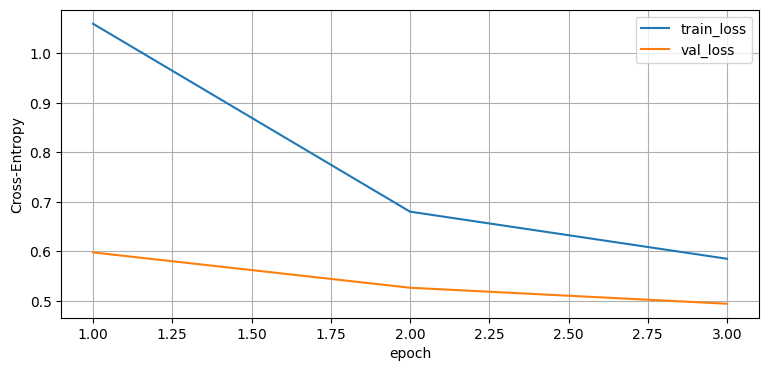

In [37]:
history = []
best_val_loss = float("inf")

for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(train_loader, training=True)
    val_loss = run_epoch(val_loader, training=False)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
    })

    print(
        f"Эпоха {epoch}: "
        f"train_loss = {train_loss:.4f}, "
        f"val_loss = {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        model.save_pretrained(SAVE_DIR)
        tokenizer.save_pretrained(SAVE_DIR)
        print("Сохранена лучшая модель.")

history_df = pd.DataFrame(history)
display(history_df)

history_df.plot(
    x="epoch",
    y=["train_loss", "val_loss"],
    figsize=(9, 4),
    ylabel="Cross-Entropy",
    grid=True,
)
plt.show()

## Генерация

In [38]:
optimizer = None

tokenizer = T5Tokenizer.from_pretrained(SAVE_DIR)
model = MT5ForConditionalGeneration.from_pretrained(
    SAVE_DIR,
    dtype=torch.float32,
).to(device)
model.eval()

@torch.inference_mode()
def translate(text):
    model.eval()
    text = clean_text(text)
    if not text:
        return ""

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=False,
    )

    if inputs["input_ids"].shape[1] > MAX_LENGTH:
        raise ValueError(f"Текст длиннее {MAX_LENGTH} токенов.")

    output = model.generate(
        **inputs.to(device),
        max_new_tokens=MAX_LENGTH,
        num_beams=4,
        do_sample=False,
        no_repeat_ngram_size=3,
        repetition_penalty=1.1,
        use_cache=True,
    )

    if output[0, -1].item() != tokenizer.eos_token_id:
        print("Достигнут лимит генерации: ответ может быть неполным.")

    return tokenizer.decode(output[0], skip_special_tokens=True)

Loading weights: 100%|██████████| 190/190 [00:00<00:00, 1441.33it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


In [39]:
example_indices = (
    token_lengths.loc[val_df.index]
    .max(axis=1)
    .nsmallest(3)
    .index
)

for index in example_indices:
    row = val_df.loc[index]

    print(f"\nПара {index}")
    print("ОРИГИНАЛ:\n", row["chunk"])
    print("\nЭТАЛОН:\n", row["translate"])
    print("\nМОДЕЛЬ:\n", translate(row["chunk"]))
    print("\n" + "=" * 80)


Пара 44
ОРИГИНАЛ:
 – Вы, я думаю, привыкли к этим великолепным картинам? – сказал я ему.

– Да-с, и к свисту пули можно привыкнуть, то есть привыкнуть скрывать невольное биение сердца.

– Я слышал напротив, что для иных старых воинов эта музыка даже приятна.

– Разумеется, если хотите, оно и приятно; только все же потому, что сердце бьется сильнее. Посмотрите, – прибавил он, указывая на восток, – что за край!

ЭТАЛОН:
 — вы походу уже привыкли к такому имбовому визуалу? — кинул я ему.

— ну да чел и к звуку прилета можно привыкнуть. типа просто учишься не палить что у тебя сердце жестко колотится.

— а я слышал наоборот что для некоторых олдов этот звук чисто как любимый трек.

— ну базару ноль если хочешь это реально по кайфу. но только потому что пульс бустится до предела. зачекайте — добавил он и показал на восток — что за локация!

МОДЕЛЬ:
 – Вы, я думаю, привыкли к этим имбовым картинам? – сказал я ему. – Да-с, и к свисту пули можно привыкнуть, то есть привыкнуться скрывать невол

Первая моя модель просто всё копирует, дай Бог пару раз поменяла результат. Есть гипотеза что это из-за слабой агрессивности перевода в примерах которые я оставил и из-за того что лосс мало штрафует когда оставляешь всё как есть. Поменяю сначала данные, а потом переобучу с другим лоссом.

## Попытка 2

### Обработка данных

In [40]:
from difflib import SequenceMatcher

train_df_v1 = train_df.copy()
history_v1 = history_df.copy()

heldout_ids = val_df.index.union(test_df.index)

audit_pool = df_clean.drop(index=heldout_ids).copy()

print("Первый train:", len(train_df_v1))
print("Пул для анализа:", len(audit_pool))
print("Зафиксированная validation:", len(val_df))
print("Зафиксированный test:", len(test_df))

Первый train: 2600
Пул для анализа: 2963
Зафиксированная validation: 325
Зафиксированный test: 325


#### Подсчёт метрик

In [41]:
def word_diff(source, target):
    a = re.findall(r"\w+", source)
    b = re.findall(r"\w+", target)

    matcher = SequenceMatcher(
        None,
        [word.casefold() for word in a],
        [word.casefold() for word in b],
        autojunk=False,
    )
    return a, b, matcher.get_opcodes()


def pair_metrics(source, target):
    a, b, operations = word_diff(source, target)
    n, m = len(a), len(b)

    common = sum(
        a2 - a1
        for tag, a1, a2, b1, b2 in operations
        if tag == "equal"
    )
    replacements = [
        (a2 - a1, b2 - b1)
        for tag, a1, a2, b1, b2 in operations
        if tag == "replace"
    ]
    last = operations[-1] if operations else ("equal", 0, 0, 0, 0)

    return {
        "source_words": n,
        "target_words": m,
        "has_words": n > 0 and m > 0,
        "char_ratio": len(target) / max(len(source), 1),
        "word_ratio": m / max(n, 1),
        "source_kept": common / max(n, 1),
        "target_kept": common / max(m, 1),
        "edit_share": (m - common) / max(m, 1),
        "replace_blocks": len(replacements),
        "replaced_source": sum(x for x, y in replacements),
        "replaced_target": sum(y for x, y in replacements),
        "inserted": sum(
            b2 - b1
            for tag, a1, a2, b1, b2 in operations
            if tag == "insert"
        ),
        "deleted": sum(
            a2 - a1
            for tag, a1, a2, b1, b2 in operations
            if tag == "delete"
        ),
        "tail_source": (
            (n - last[1]) / max(n, 1) if last[0] != "equal" else 0
        ),
        "tail_target": (
            (m - last[3]) / max(m, 1) if last[0] != "equal" else 0
        ),
    }


audit = pd.DataFrame(
    [
        pair_metrics(row.chunk, row.translate)
        for row in audit_pool.itertuples()
    ],
    index=audit_pool.index,
)

audit["in_train_v1"] = audit.index.isin(train_df_v1.index)
audit["old_ratio_pass"] = audit.index.isin(df_filtered.index)

audit["possible_cut"] = (
    (audit["tail_source"] >= 0.15)
    & (audit["tail_target"] <= 0.05)
)
audit["possible_append"] = (
    (audit["tail_target"] >= 0.15)
    & (audit["tail_source"] <= 0.05)
)

for column, name in [
    ("chunk", "source_tokens"),
    ("translate", "target_tokens"),
]:
    ids = tokenizer(
        audit_pool[column].tolist(),
        padding=False,
        truncation=False,
        return_attention_mask=False,
    )["input_ids"]
    audit[name] = [len(sequence) for sequence in ids]
    del ids

audit["fits_length"] = audit[
    ["source_tokens", "target_tokens"]
].le(MAX_LENGTH).all(axis=1)

display(audit.head().round(3))

,source_words,target_words,has_words,char_ratio,word_ratio,source_kept,target_kept,edit_share,replace_blocks,replaced_source,...,deleted,tail_source,tail_target,in_train_v1,old_ratio_pass,possible_cut,possible_append,source_tokens,target_tokens,fits_length
0,154,142,True,0.910,0.922,0.260,0.282,0.718,27,108,...,6,0.000,0.000,True,True,False,False,304,311,True
2,131,136,True,1.010,1.038,0.420,0.404,0.596,18,71,...,5,0.000,0.000,True,True,False,False,278,295,True
3,161,166,True,0.937,1.031,0.391,0.380,0.620,30,95,...,3,0.019,0.030,True,True,False,False,378,338,True
5,123,139,True,1.047,1.130,0.593,0.525,0.475,24,47,...,3,0.000,0.022,True,True,False,False,286,299,True
6,135,150,True,1.032,1.111,0.519,0.467,0.533,30,62,...,3,0.030,0.060,True,True,False,False,279,299,True


#### Конкретные пары

In [42]:
def show_pair(index, full_text=True, max_changes=12):
    row = audit_pool.loc[index]
    a, b, operations = word_diff(row["chunk"], row["translate"])

    columns = [
        "source_words", "target_words",
        "char_ratio", "word_ratio",
        "source_kept", "target_kept", "edit_share",
        "replace_blocks", "inserted", "deleted",
        "possible_cut", "possible_append",
    ]
    display(audit.loc[[index], columns].round(3))

    if full_text:
        print("ОРИГИНАЛ:\n", row["chunk"])
        print("\nПЕРЕВОД:\n", row["translate"])

    names = {
        "replace": "Замена блока",
        "insert": "Добавление",
        "delete": "Удаление",
    }
    changes = [
        {
            "тип": names[tag],
            "было": " ".join(a[a1:a2]) or "—",
            "стало": " ".join(b[b1:b2]) or "—",
        }
        for tag, a1, a2, b1, b2 in operations
        if tag != "equal"
    ]

    print(f"\nИзменённых блоков: {len(changes)}")

    if changes:
        with pd.option_context("display.max_colwidth", None):
            display(pd.DataFrame(changes).head(max_changes))
        if len(changes) > max_changes:
            print(f"Показаны первые {max_changes} блоков.")


show_pair(21)

,source_words,target_words,char_ratio,word_ratio,source_kept,target_kept,edit_share,replace_blocks,inserted,deleted,possible_cut,possible_append
21,7,13,1.467,1.857,0.714,0.385,0.615,2,1,0,False,False


ОРИГИНАЛ:
 «А! Казбич!» – подумал я и вспомнил кольчугу.

ПЕРЕВОД:
 окак казбич подумал я и сразу вспомнил про тот броник под его худи

Изменённых блоков: 3


,тип,было,стало
0,Замена блока,А,окак
1,Добавление,—,сразу
2,Замена блока,кольчугу,про тот броник под его худи


In [45]:
groups = {
    "Почти копия": audit["edit_share"] < 0.05,
    "Много изменений при близких длинах": (
        (audit["edit_share"] >= 0.30)
        & audit["word_ratio"].between(0.9, 1.1)
    ),
    "Перевод заметно длиннее": (
        (audit["word_ratio"] > 1.2)
        & (audit["edit_share"] >= 0.30)
    ),
    "Возможный обрыв": audit["possible_cut"],
    "Возможное дополнение": audit["possible_append"],
    "Не прошли прежний ratio": ~audit["old_ratio_pass"],
}

samples = []

for name, mask in groups.items():
    candidates = audit.loc[mask & audit["fits_length"]]
    if len(candidates):
        sample = candidates.sample(
            n=min(3, len(candidates)),
            random_state=42,
        )
        samples.append(sample.assign(group=name))

review_sample = pd.concat(samples).rename_axis("pair_id")

display(
    review_sample[
        [
            "group", "source_words", "target_words",
            "word_ratio", "edit_share",
            "replaced_target", "inserted", "deleted",
        ]
    ].round(3)
)

review_decisions = {
    2513: ("exclude", "Перевод оборван в первом предложении."),
    3511: ("exclude", "Заголовку сопоставлен большой пересказ."),
}

,group,source_words,target_words,word_ratio,edit_share,replaced_target,inserted,deleted
pair_id,,,,,,,,
2940,Почти копия,497,494,0.994,0.038,19,0,1
2155,Почти копия,428,432,1.009,0.037,16,0,1
2553,Почти копия,455,453,0.996,0.007,3,0,0
471,Много изменений при близких длинах,253,266,1.051,0.624,146,20,5
130,Много изменений при близких длинах,164,151,0.921,0.536,72,9,17
20,Много изменений при близких длинах,191,195,1.021,0.513,92,8,7
292,Перевод заметно длиннее,243,317,1.305,0.811,210,47,3
38,Перевод заметно длиннее,32,42,1.312,0.619,24,2,0
333,Перевод заметно длиннее,252,304,1.206,0.622,170,19,6


#### Графики и финальная выборка

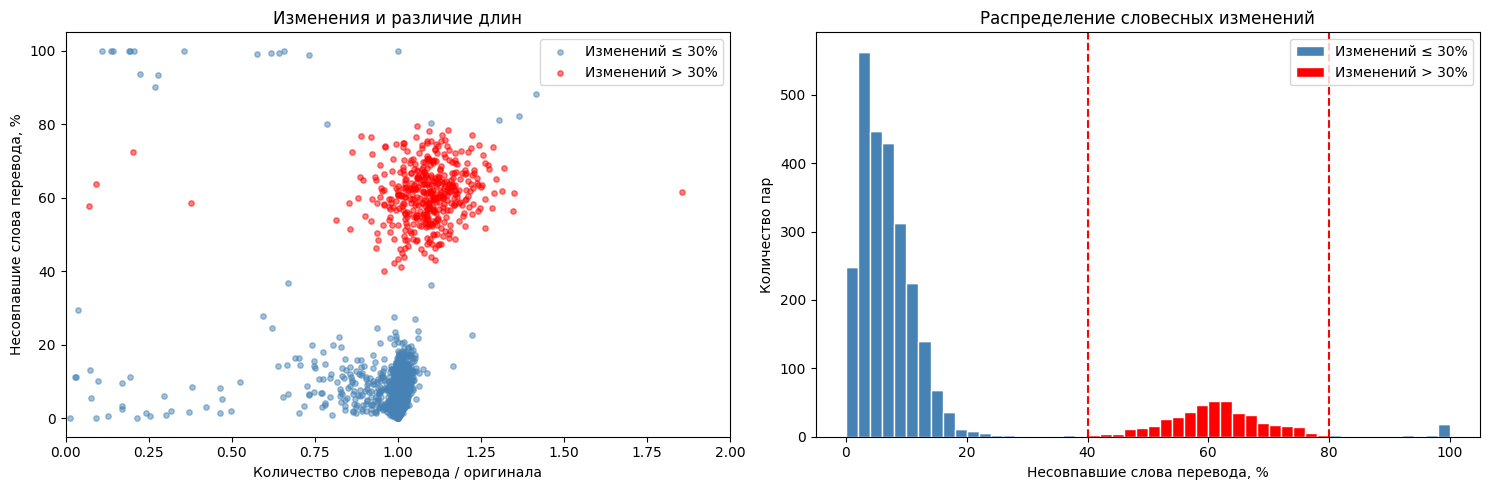

Изменений > 30%: 433 из 2963 пар (14.61%)


In [63]:
edit_left = 0.4
edit_right = 0.8

high_edit = audit["edit_share"].between(edit_left, edit_right)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for mask, color, label in [
    (~high_edit, "steelblue", "Изменений ≤ 30%"),
    (high_edit, "red", "Изменений > 30%"),
]:
    axes[0].scatter(
        audit.loc[mask, "word_ratio"],
        audit.loc[mask, "edit_share"] * 100,
        s=15,
        alpha=0.5,
        color=color,
        label=label,
    )

axes[0].set_xlim(0, 2)
axes[0].set_xlabel("Количество слов перевода / оригинала")
axes[0].set_ylabel("Несовпавшие слова перевода, %")
axes[0].set_title("Изменения и различие длин")
axes[0].legend()

axes[1].hist(
    [
        audit.loc[~high_edit, "edit_share"] * 100,
        audit.loc[high_edit, "edit_share"] * 100,
    ],
    bins=np.linspace(0, 100, 51),
    stacked=True,
    color=["steelblue", "red"],
    label=["Изменений ≤ 30%", "Изменений > 30%"],
    edgecolor="white",
)
axes[1].axvline(edit_left*100, color="red", linestyle="--")
axes[1].axvline(edit_right*100, color="red", linestyle="--")
axes[1].set_xlabel("Несовпавшие слова перевода, %")
axes[1].set_ylabel("Количество пар")
axes[1].set_title("Распределение словесных изменений")
axes[1].legend()

plt.tight_layout()
plt.show()

print(
    f"Изменений > 30%: {high_edit.sum()} из {len(audit)} пар "
    f"({high_edit.mean():.2%})"
)

In [65]:
decisions = pd.Series(
    {index: value[0] for index, value in review_decisions.items()},
    dtype="object",
).reindex(audit.index)

approved = decisions.eq("keep")
rejected = decisions.isin(["exclude", "uncertain"])

suspicious_tail = audit["possible_cut"] | audit["possible_append"]

eligible = (
    audit["has_words"]
    & audit["fits_length"]
    & (
        (audit["in_train_v1"] & ~suspicious_tail)
        | approved
    )
    & ~rejected
)

threshold_rows = []

for threshold in [0, 0.01, 0.03, 0.05, 0.10]:
    selected = eligible & audit["edit_share"].ge(threshold)

    threshold_rows.append({
        "минимум изменений, %": threshold * 100,
        "всего пар": int(selected.sum()),
        "из прежнего train": int(
            (selected & audit["in_train_v1"]).sum()
        ),
        "одобренных дополнительных": int(
            (selected & ~audit["in_train_v1"]).sum()
        ),
    })

display(pd.DataFrame(threshold_rows))

,"минимум изменений, %",всего пар,из прежнего train,одобренных дополнительных
0,0.0,2598,2598,0
1,1.0,2565,2565,0
2,3.0,2168,2168,0
3,5.0,1660,1660,0
4,10.0,742,742,0


In [66]:
WORD_RATIO_LEFT = 0.8
WORD_RATIO_RIGHT = 1.2

blocked_ids = [
    index
    for index, (decision, reason) in review_decisions.items()
    if decision in ("exclude", "uncertain")
]

keep_v2 = (
    audit["edit_share"].between(edit_left, edit_right)
    & audit["word_ratio"].between(WORD_RATIO_LEFT, WORD_RATIO_RIGHT)
    & audit["has_words"]
    & audit["fits_length"]
    & ~audit.index.isin(blocked_ids)
)

train_df_v2 = audit_pool.loc[keep_v2].copy()

print("Прежний train:", len(train_df_v1))
print("Новый train:", len(train_df_v2))
print("Исключено из пула:", len(audit_pool) - len(train_df_v2))

print(
    "Сохранено из прежнего train:",
    train_df_v2.index.isin(train_df_v1.index).sum(),
)
print(
    "Добавлено дополнительных пар:",
    (~train_df_v2.index.isin(train_df_v1.index)).sum(),
)

assert train_df_v2.index.intersection(val_df.index).empty
assert train_df_v2.index.intersection(test_df.index).empty

SAVE_DIR_V2 = "rut5_v2_best"

Прежний train: 2600
Новый train: 382
Исключено из пула: 2581
Сохранено из прежнего train: 281
Добавлено дополнительных пар: 101


### Обучение

#### Сетап

In [67]:
MAX_EPOCHS_V2 = 20
PATIENCE_V2 = 3
BATCH_SIZE_V2 = 1
LEARNING_RATE_V2 = 1e-4
SAVE_DIR_V2 = "rut5_v2_best"

set_seed(42)

optimizer = None

model = MT5ForConditionalGeneration.from_pretrained(
    "cointegrated/rut5-small",
    dtype=torch.float32,
).to(device)
model.gradient_checkpointing_enable()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE_V2,
)

train_loader_v2 = DataLoader(
    encode_pairs(train_df_v2),
    batch_size=BATCH_SIZE_V2,
    shuffle=True,
    collate_fn=collator,
)
val_loader_v2 = DataLoader(
    encode_pairs(val_df),
    batch_size=BATCH_SIZE_V2,
    shuffle=False,
    collate_fn=collator,
)

print("Обучающих пар:", len(train_df_v2))
print("Шагов за эпоху:", len(train_loader_v2))
print("Максимум шагов:", MAX_EPOCHS_V2 * len(train_loader_v2))

Loading weights: 100%|██████████| 190/190 [00:00<00:00, 1267.64it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Обучающих пар: 382
Шагов за эпоху: 382
Максимум шагов: 7640


#### Обучение

Validation: 100%|██████████| 325/325 [00:10<00:00, 30.64it/s]


Эпоха 1/20: train_loss = 4.0453, val_loss = 1.6799


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.16it/s]


Сохранена лучшая модель второго эксперимента.


Validation: 100%|██████████| 325/325 [00:10<00:00, 30.00it/s]


Эпоха 2/20: train_loss = 3.5380, val_loss = 1.4758


... (30 outputs left out)

Validation: 100%|██████████| 325/325 [00:10<00:00, 31.87it/s]

Эпоха 12/20: train_loss = 2.4382, val_loss = 1.0755
Эпох без улучшения: 3/3
Ранняя остановка.


,epoch,updates,train_loss,val_loss
0,1,382,4.045345,1.679874
1,2,764,3.537993,1.475830
2,3,1146,3.284077,1.285050
3,4,1528,3.114406,1.210359
4,5,1910,2.983466,1.135102
5,6,2292,2.876557,1.074902
6,7,2674,2.791456,1.079527
7,8,3056,2.705054,1.078739
8,9,3438,2.625220,1.045717
9,10,3820,2.559289,1.079553


Лучшая эпоха: 9
Лучший validation loss: 1.0457


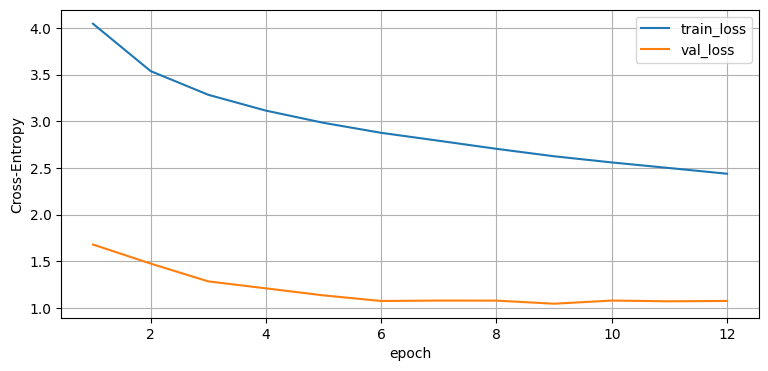

In [60]:
history_v2 = []
best_val_loss_v2 = float("inf")
best_epoch_v2 = None
bad_epochs_v2 = 0

for epoch in range(1, MAX_EPOCHS_V2 + 1):
    train_loss = run_epoch(train_loader_v2, training=True)
    val_loss = run_epoch(val_loader_v2, training=False)

    history_v2.append({
        "epoch": epoch,
        "updates": epoch * len(train_loader_v2),
        "train_loss": train_loss,
        "val_loss": val_loss,
    })

    print(
        f"Эпоха {epoch}/{MAX_EPOCHS_V2}: "
        f"train_loss = {train_loss:.4f}, "
        f"val_loss = {val_loss:.4f}"
    )

    if val_loss < best_val_loss_v2:
        best_val_loss_v2 = val_loss
        best_epoch_v2 = epoch
        bad_epochs_v2 = 0

        model.save_pretrained(SAVE_DIR_V2)
        tokenizer.save_pretrained(SAVE_DIR_V2)
        print("Сохранена лучшая модель второго эксперимента.")
    else:
        bad_epochs_v2 += 1
        print(
            f"Эпох без улучшения: "
            f"{bad_epochs_v2}/{PATIENCE_V2}"
        )

    if bad_epochs_v2 >= PATIENCE_V2:
        print("Ранняя остановка.")
        break

history_df_v2 = pd.DataFrame(history_v2)
display(history_df_v2)

print("Лучшая эпоха:", best_epoch_v2)
print(f"Лучший validation loss: {best_val_loss_v2:.4f}")

history_df_v2.plot(
    x="epoch",
    y=["train_loss", "val_loss"],
    figsize=(9, 4),
    ylabel="Cross-Entropy",
    grid=True,
)
plt.show()

Лучший checkpoint второго эксперимента загружается в следующей ячейке вместе с генерацией примеров.

### Генерация

In [68]:
optimizer = None

tokenizer = T5Tokenizer.from_pretrained(SAVE_DIR_V2)
model = MT5ForConditionalGeneration.from_pretrained(
    SAVE_DIR_V2,
    dtype=torch.float32,
).to(device)
model.eval()

example_predictions_v2 = {}

for index in example_indices:
    row = val_df.loc[index]
    prediction = translate(row["chunk"])
    example_predictions_v2[index] = prediction

    print(f"\nПара {index}")
    print("ОРИГИНАЛ:\n", row["chunk"])
    print("\nЭТАЛОН:\n", row["translate"])
    print("\nМОДЕЛЬ V2:\n", prediction)
    print("\n" + "=" * 80)

Loading weights: 100%|██████████| 190/190 [00:00<00:00, 1208.65it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.



Пара 44
ОРИГИНАЛ:
 – Вы, я думаю, привыкли к этим великолепным картинам? – сказал я ему.

– Да-с, и к свисту пули можно привыкнуть, то есть привыкнуть скрывать невольное биение сердца.

– Я слышал напротив, что для иных старых воинов эта музыка даже приятна.

– Разумеется, если хотите, оно и приятно; только все же потому, что сердце бьется сильнее. Посмотрите, – прибавил он, указывая на восток, – что за край!

ЭТАЛОН:
 — вы походу уже привыкли к такому имбовому визуалу? — кинул я ему.

— ну да чел и к звуку прилета можно привыкнуть. типа просто учишься не палить что у тебя сердце жестко колотится.

— а я слышал наоборот что для некоторых олдов этот звук чисто как любимый трек.

— ну базару ноль если хочешь это реально по кайфу. но только потому что пульс бустится до предела. зачекайте — добавил он и показал на восток — что за локация!

МОДЕЛЬ V2:
 — вы, я думаю, привыкли к этим великолепным картинам? — выдал я ему. — да-с, и к свисту пули можно привыкнуть, то есть привыкнуться скрыват

Теперь оно галюнит и слишком сильно всё меняет. Надо совместить выборки.

## Попытка 3

### Отбор данных

In [77]:
moderate_mask = (
    audit.index.isin(train_df_v1.index)
    & ~audit.index.isin(train_df_v2.index)
    & audit["edit_share"].between(0.1, 0.40, inclusive="left")
    & audit["word_ratio"].between(WORD_RATIO_LEFT, WORD_RATIO_RIGHT)
    & audit["has_words"]
    & audit["fits_length"]
    & ~audit.index.isin(blocked_ids)
)

returned_pairs = audit_pool.loc[moderate_mask].copy()

train_df_v3 = pd.concat([
    train_df_v2,
    returned_pairs,
])

assert train_df_v3.index.is_unique
assert train_df_v3.index.intersection(val_df.index).empty
assert train_df_v3.index.intersection(test_df.index).empty

print("Сильно изменённые пары V2:", len(train_df_v2))
print("Возвращено умеренно изменённых:", len(returned_pairs))
print("Всего в train V3:", len(train_df_v3))

SAVE_DIR_V3 = "rut5_v3_best"

Сильно изменённые пары V2: 382
Возвращено умеренно изменённых: 459
Всего в train V3: 841


### Сетап

In [78]:
from difflib import SequenceMatcher
import torch.nn.functional as F

EDIT_WEIGHT = 2.5


def encode_weighted_pairs(frame):
    examples = encode_pairs(frame)

    for example in examples:
        source = example["input_ids"]
        target = example["labels"]
        weights = [1.0] * len(target)

        matcher = SequenceMatcher(
            None, source, target, autojunk=False
        )

        for tag, _, _, start, end in matcher.get_opcodes():
            if tag in ("replace", "insert"):
                weights[start:end] = [EDIT_WEIGHT] * (end - start)

        example["loss_weights"] = weights

    return examples


def weighted_collator(features):
    features = [dict(feature) for feature in features]
    weights = [feature.pop("loss_weights") for feature in features]

    batch = collator(features)
    padded_weights = torch.zeros_like(
        batch["labels"], dtype=torch.float32
    )

    for i, example_weights in enumerate(weights):
        valid_positions = batch["labels"][i].ne(-100)
        padded_weights[i, valid_positions] = torch.tensor(
            example_weights, dtype=torch.float32
        )

    batch["loss_weights"] = padded_weights
    return batch

In [79]:
MAX_EPOCHS_V3 = 7
PATIENCE_V3 = 3
BATCH_SIZE_V3 = 1
LEARNING_RATE_V3 = 1e-4
SAVE_DIR_V3 = "rut5_v3_weighted_best"

set_seed(42)

optimizer = None

model = MT5ForConditionalGeneration.from_pretrained(
    "cointegrated/rut5-small",
    dtype=torch.float32,
).to(device)
model.gradient_checkpointing_enable()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE_V3,
)

train_loader_v3 = DataLoader(
    encode_weighted_pairs(train_df_v3),
    batch_size=BATCH_SIZE_V3,
    shuffle=True,
    collate_fn=weighted_collator,
)

val_loader_v3 = DataLoader(
    encode_weighted_pairs(val_df),
    batch_size=BATCH_SIZE_V3,
    shuffle=False,
    collate_fn=weighted_collator,
)

print("Обучающих пар:", len(train_df_v3))
print("Валидационных пар:", len(val_df))
print("Шагов за эпоху:", len(train_loader_v3))
print("Максимум шагов:", MAX_EPOCHS_V3 * len(train_loader_v3))

Loading weights: 100%|██████████| 190/190 [00:00<00:00, 1449.99it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Обучающих пар: 841
Валидационных пар: 325
Шагов за эпоху: 841
Максимум шагов: 5887


### Обучение

In [80]:
def run_epoch_v3(loader, training):
    model.train(training)

    weighted_sum = 0.0
    weight_sum = 0.0
    ce_sum = 0.0
    token_count = 0

    with torch.set_grad_enabled(training):
        for batch in tqdm(
            loader,
            desc="Train" if training else "Validation",
        ):
            batch = {
                name: tensor.to(device)
                for name, tensor in batch.items()
            }

            weights = batch.pop("loss_weights")
            labels = batch["labels"]

            if training:
                optimizer.zero_grad(set_to_none=True)

            outputs = model(**batch, use_cache=False)

            token_losses = F.cross_entropy(
                outputs.logits.transpose(1, 2),
                labels,
                reduction="none",
                ignore_index=-100,
            )

            loss_sum = (token_losses * weights).sum()
            batch_weight = weights.sum()
            loss = loss_sum / batch_weight

            if not torch.isfinite(loss):
                raise RuntimeError("Получен бесконечный loss или NaN.")

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    1.0,
                    error_if_nonfinite=True,
                )
                optimizer.step()

            weighted_sum += loss_sum.item()
            weight_sum += batch_weight.item()
            ce_sum += token_losses.sum().item()
            token_count += labels.ne(-100).sum().item()

    return weighted_sum / weight_sum, ce_sum / token_count

Validation: 100%|██████████| 325/325 [00:17<00:00, 18.43it/s]


Эпоха 1/7: train_weighted = 3.4455, val_weighted = 1.1791, val_ce = 0.6987


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  6.74it/s]


Сохранена лучшая модель V3 со взвешенным loss.


Validation: 100%|██████████| 325/325 [00:18<00:00, 17.46it/s]


Эпоха 2/7: train_weighted = 2.6719, val_weighted = 1.0331, val_ce = 0.5898


... (20 outputs left out)

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  5.87it/s]

Сохранена лучшая модель V3 со взвешенным loss.


,epoch,updates,train_loss,val_loss,train_ce,val_ce
0,1,841,3.445466,1.179085,2.777149,0.698661
1,2,1682,2.671905,1.033073,2.022849,0.589779
2,3,2523,2.396759,0.949488,1.781415,0.536044
3,4,3364,2.213779,0.897809,1.625129,0.503753
4,5,4205,2.093097,0.847073,1.526872,0.487550
5,6,5046,1.988939,0.840998,1.443482,0.473172
6,7,5887,1.912475,0.798964,1.386393,0.455867


Лучшая эпоха: 7
Лучший взвешенный validation loss: 0.7990


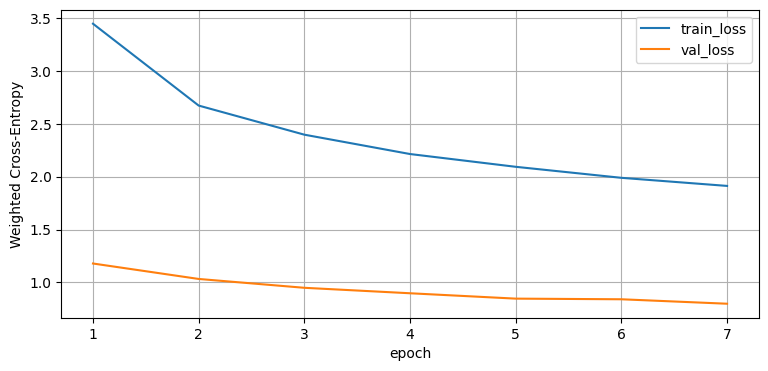

In [81]:
history_v3 = []
best_val_loss_v3 = float("inf")
best_epoch_v3 = None
bad_epochs_v3 = 0

for epoch in range(1, MAX_EPOCHS_V3 + 1):
    train_loss, train_ce = run_epoch_v3(
        train_loader_v3, training=True
    )
    val_loss, val_ce = run_epoch_v3(
        val_loader_v3, training=False
    )

    history_v3.append({
        "epoch": epoch,
        "updates": epoch * len(train_loader_v3),
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_ce": train_ce,
        "val_ce": val_ce,
    })

    print(
        f"Эпоха {epoch}/{MAX_EPOCHS_V3}: "
        f"train_weighted = {train_loss:.4f}, "
        f"val_weighted = {val_loss:.4f}, "
        f"val_ce = {val_ce:.4f}"
    )

    if val_loss < best_val_loss_v3:
        best_val_loss_v3 = val_loss
        best_epoch_v3 = epoch
        bad_epochs_v3 = 0

        model.save_pretrained(SAVE_DIR_V3)
        tokenizer.save_pretrained(SAVE_DIR_V3)
        print("Сохранена лучшая модель V3 со взвешенным loss.")
    else:
        bad_epochs_v3 += 1
        print(
            f"Эпох без улучшения: "
            f"{bad_epochs_v3}/{PATIENCE_V3}"
        )

    if bad_epochs_v3 >= PATIENCE_V3:
        print("Ранняя остановка.")
        break

history_df_v3 = pd.DataFrame(history_v3)
display(history_df_v3)

print("Лучшая эпоха:", best_epoch_v3)
print(f"Лучший взвешенный validation loss: {best_val_loss_v3:.4f}")

history_df_v3.plot(
    x="epoch",
    y=["train_loss", "val_loss"],
    figsize=(9, 4),
    ylabel="Weighted Cross-Entropy",
    grid=True,
)
plt.show()

### Генерация

In [83]:
from pathlib import Path

checkpoint_path = Path("rut5_v3_weighted_best").resolve()
assert checkpoint_path.is_dir(), checkpoint_path

optimizer = None

tokenizer = T5Tokenizer.from_pretrained(str(checkpoint_path))
model = MT5ForConditionalGeneration.from_pretrained(
    str(checkpoint_path),
    dtype=torch.float32,
).to(device)
model.eval()

print("Checkpoint:", checkpoint_path)
print("Устройство:", next(model.parameters()).device)

example_predictions_v3 = {}

Loading weights: 100%|██████████| 190/190 [00:00<00:00, 1108.26it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Checkpoint: C:\proga\p\pasha\notebooks\vvii\case\rut5_v3_weighted_best
Устройство: cuda:0


In [84]:
for index in example_indices:
    row = val_df.loc[index]
    prediction = translate(row["chunk"])
    example_predictions_v3[index] = prediction

    print(f"\nПара {index}")
    print("ОРИГИНАЛ:\n", row["chunk"])
    print("\nЭТАЛОН:\n", row["translate"])
    print("\nМОДЕЛЬ V3:\n", prediction)
    print("\n" + "=" * 80)

Loading weights: 100%|██████████| 190/190 [00:00<00:00, 1261.60it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.



Пара 44
ОРИГИНАЛ:
 – Вы, я думаю, привыкли к этим великолепным картинам? – сказал я ему.

– Да-с, и к свисту пули можно привыкнуть, то есть привыкнуть скрывать невольное биение сердца.

– Я слышал напротив, что для иных старых воинов эта музыка даже приятна.

– Разумеется, если хотите, оно и приятно; только все же потому, что сердце бьется сильнее. Посмотрите, – прибавил он, указывая на восток, – что за край!

ЭТАЛОН:
 — вы походу уже привыкли к такому имбовому визуалу? — кинул я ему.

— ну да чел и к звуку прилета можно привыкнуть. типа просто учишься не палить что у тебя сердце жестко колотится.

— а я слышал наоборот что для некоторых олдов этот звук чисто как любимый трек.

— ну базару ноль если хочешь это реально по кайфу. но только потому что пульс бустится до предела. зачекайте — добавил он и показал на восток — что за локация!

МОДЕЛЬ V3:
 — вы, я думаю, привыкли к этим имбовым картинам? — выдал я ему. — да-с, и к свисту пули можно привыкнуть, то есть привыкнуться скрывать нев

Всё равно чёто не очень, поэтому попробую ещё одну дебильную идею.

## Попытка 4: Базированный словарь

### Словарь

In [85]:
import json
import random
import re

with open("youth_replacements.json", encoding="utf-8") as file:
    slang_dictionary = json.load(file)

excluded_keys = {
    "легко",
    "вне себя",
    "серьезно",
    "прошлое",
    "прекрасно",
    "отлично",
    "замечательно",
}

working_dictionary = {
    key: variants
    for key, variants in slang_dictionary.items()
    if key not in excluded_keys
}

replacement_pattern = re.compile(
    r"(?<!\w)(?:"
    + "|".join(
        re.escape(key)
        for key in sorted(working_dictionary, key=len, reverse=True)
    )
    + r")(?!\w)",
    flags=re.IGNORECASE,
)

rng = random.Random(42)
rows = []

for source_id, row in train_df_v3.iterrows():
    text = re.sub(r"\s+", " ", row["chunk"]).strip()

    fragments = re.split(
        r'(?<=[.!?…])\s+(?=[А-ЯЁ«"—–])',
        text,
    )

    for source in fragments:
        if not 8 <= len(re.findall(r"\w+", source)) <= 40:
            continue

        if re.search(r"\[\d", source):
            continue

        first_letter = re.search(r"[А-ЯЁа-яё]", source)

        if not first_letter or not first_letter.group().isupper():
            continue

        matches = list(replacement_pattern.finditer(source))

        if not matches:
            continue

        selected = rng.sample(matches, min(2, len(matches)))
        target = source
        changes = []

        for match in sorted(
            selected, key=lambda match: match.start(), reverse=True
        ):
            key = match.group().lower()
            replacement = rng.choice(working_dictionary[key])

            if match.group().isupper():
                replacement = replacement.upper()
            elif match.group()[0].isupper():
                replacement = replacement[0].upper() + replacement[1:]

            target = (
                target[:match.start()]
                + replacement
                + target[match.end():]
            )

            changes.append(f"{key} → {replacement}")

        rows.append({
            "source_id": source_id,
            "chunk": source,
            "translate": target,
            "main_key": selected[0].group().lower(),
            "changes": "; ".join(reversed(changes)),
        })

synthetic_candidates_v3 = (
    pd.DataFrame(rows)
    .drop_duplicates(subset=["chunk", "translate"])
    .sample(frac=1, random_state=42)
    .groupby("main_key", sort=False)
    .head(4)
    .reset_index(drop=True)
)

print("Черновых пар:", len(synthetic_candidates_v3))
print(
    "Основных ключей:",
    synthetic_candidates_v3["main_key"].nunique(),
)

Черновых пар: 680
Основных ключей: 287


In [88]:
import math

SYNTHETIC_SHARE = 0.25

synthetic_count = math.ceil(
    len(train_df_v3)
    * SYNTHETIC_SHARE
    / (1 - SYNTHETIC_SHARE)
)

assert len(synthetic_candidates_v3) >= synthetic_count, (
    f"Нужно {synthetic_count} синтетических пар, "
    f"доступно {len(synthetic_candidates_v3)}."
)

synthetic_df_v3 = synthetic_candidates_v3.sample(
    n=synthetic_count,
    random_state=42,
).copy()

assert synthetic_df_v3["source_id"].isin(train_df_v3.index).all()
assert not synthetic_df_v3["source_id"].isin(
    val_df.index.union(test_df.index)
).any()

train_data_v3 = pd.concat([
    train_df_v3[["chunk", "translate"]],
    synthetic_df_v3[["chunk", "translate"]],
], ignore_index=True)

print("Исходных пар:", len(train_df_v3))
print("Синтетических пар:", len(synthetic_df_v3))
print("Всего:", len(train_data_v3))
print(
    "Доля синтетики:",
    f"{len(synthetic_df_v3) / len(train_data_v3):.1%}",
)

Исходных пар: 841
Синтетических пар: 281
Всего: 1122
Доля синтетики: 25.0%


### Обучение

In [90]:
EDIT_WEIGHT = 4.0

MAX_EPOCHS_V3_SYNTH = 7
PATIENCE_V3_SYNTH = 3
SAVE_DIR_V3_SYNTH = "rut5_v3_synthetic25_w4_best"

set_seed(42)

optimizer = None
model = None

model = MT5ForConditionalGeneration.from_pretrained(
    "cointegrated/rut5-small",
    dtype=torch.float32,
).to(device)
model.gradient_checkpointing_enable()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
)

train_features_v3_synth = encode_weighted_pairs(train_data_v3)
val_features_v3_synth = encode_weighted_pairs(val_df)

assert all(
    len(example["input_ids"]) <= MAX_LENGTH
    and len(example["labels"]) <= MAX_LENGTH
    for example in train_features_v3_synth + val_features_v3_synth
), "В данных появился слишком длинный пример."

train_loader_v3_synth = DataLoader(
    train_features_v3_synth,
    batch_size=1,
    shuffle=True,
    collate_fn=weighted_collator,
)

val_loader_v3_synth = DataLoader(
    val_features_v3_synth,
    batch_size=1,
    shuffle=False,
    collate_fn=weighted_collator,
)

print("Вес изменённых токенов:", EDIT_WEIGHT)
print("Шагов за эпоху:", len(train_loader_v3_synth))
print(
    "Максимум шагов:",
    MAX_EPOCHS_V3_SYNTH * len(train_loader_v3_synth),
)

Loading weights: 100%|██████████| 190/190 [00:00<00:00, 1202.36it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Вес изменённых токенов: 4.0
Шагов за эпоху: 1122
Максимум шагов: 7854


In [92]:
history_v3_synth = []
best_val_loss_v3_synth = float("inf")
best_epoch_v3_synth = None
bad_epochs_v3_synth = 0

for epoch in range(1, MAX_EPOCHS_V3_SYNTH + 1):
    train_loss, train_ce = run_epoch_v3(
        train_loader_v3_synth, training=True
    )
    val_loss, val_ce = run_epoch_v3(
        val_loader_v3_synth, training=False
    )

    history_v3_synth.append({
        "epoch": epoch,
        "updates": epoch * len(train_loader_v3_synth),
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_ce": train_ce,
        "val_ce": val_ce,
    })

    print(
        f"Эпоха {epoch}/{MAX_EPOCHS_V3_SYNTH}: "
        f"train_weighted = {train_loss:.4f}, "
        f"val_weighted = {val_loss:.4f}, "
        f"val_ce = {val_ce:.4f}"
    )

    if val_loss < best_val_loss_v3_synth:
        best_val_loss_v3_synth = val_loss
        best_epoch_v3_synth = epoch
        bad_epochs_v3_synth = 0

        model.save_pretrained(SAVE_DIR_V3_SYNTH)
        tokenizer.save_pretrained(SAVE_DIR_V3_SYNTH)
        pd.DataFrame([history_v3_synth[-1]]).to_csv(
            f"{SAVE_DIR_V3_SYNTH}/checkpoint_metrics.csv",
            index=False,
        )
        print("Сохранён лучший checkpoint.")
    else:
        bad_epochs_v3_synth += 1
        print(
            f"Эпох без улучшения: "
            f"{bad_epochs_v3_synth}/{PATIENCE_V3_SYNTH}"
        )

    if bad_epochs_v3_synth >= PATIENCE_V3_SYNTH:
        print("Ранняя остановка.")
        break

history_df_v3_synth = pd.DataFrame(history_v3_synth)
display(history_df_v3_synth)

print("Лучшая эпоха:", best_epoch_v3_synth)

history_df_v3_synth.plot(
    x="epoch",
    y=["train_loss", "val_loss"],
    figsize=(9, 4),
    ylabel="Weighted Cross-Entropy",
    grid=True,
)
plt.show()

Train:   6%|▌         | 63/1122 [00:10<02:52,  6.14it/s]


KeyboardInterrupt: 

In [93]:
from pathlib import Path

checkpoint_path = Path(SAVE_DIR_V3_SYNTH).resolve()
assert checkpoint_path.is_dir(), checkpoint_path

optimizer = None
model = None

tokenizer = T5Tokenizer.from_pretrained(str(checkpoint_path))
model = MT5ForConditionalGeneration.from_pretrained(
    str(checkpoint_path),
    dtype=torch.float32,
).to(device)
model.eval()

print("Загружен checkpoint:", checkpoint_path)
print("Устройство:", next(model.parameters()).device)

val_predictions_v3_synth = {}

Loading weights: 100%|██████████| 190/190 [00:00<00:00, 1105.79it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Загружен checkpoint: C:\proga\p\pasha\notebooks\vvii\case\rut5_v3_synthetic25_w4_best
Устройство: cuda:0


### Генерация

In [95]:
review_indices_v3_synth = example_indices.append(
    val_df.drop(index=example_indices)
    .sample(n=2, random_state=42)
    .index
)

example_predictions_v3_synth = {}

for index in review_indices_v3_synth:
    row = val_df.loc[index]
    if index not in val_predictions_v3_synth:
        val_predictions_v3_synth[index] = translate(row["chunk"])
    prediction = val_predictions_v3_synth[index]
    example_predictions_v3_synth[index] = prediction

    print(f"\nПара {index}")
    print("ОРИГИНАЛ:\n", row["chunk"])
    print("\nЭТАЛОН:\n", row["translate"])

    if index in example_predictions_v3:
        print(
            "\nПРЕДЫДУЩАЯ V3:\n",
            example_predictions_v3[index],
        )

    print("\nМОДЕЛЬ С СИНТЕТИКОЙ:\n", prediction)
    print("\n" + "=" * 80)


Пара 44
ОРИГИНАЛ:
 – Вы, я думаю, привыкли к этим великолепным картинам? – сказал я ему.

– Да-с, и к свисту пули можно привыкнуть, то есть привыкнуть скрывать невольное биение сердца.

– Я слышал напротив, что для иных старых воинов эта музыка даже приятна.

– Разумеется, если хотите, оно и приятно; только все же потому, что сердце бьется сильнее. Посмотрите, – прибавил он, указывая на восток, – что за край!

ЭТАЛОН:
 — вы походу уже привыкли к такому имбовому визуалу? — кинул я ему.

— ну да чел и к звуку прилета можно привыкнуть. типа просто учишься не палить что у тебя сердце жестко колотится.

— а я слышал наоборот что для некоторых олдов этот звук чисто как любимый трек.

— ну базару ноль если хочешь это реально по кайфу. но только потому что пульс бустится до предела. зачекайте — добавил он и показал на восток — что за локация!

ПРЕДЫДУЩАЯ V3:
 — вы, я думаю, привыкли к этим имбовым картинам? — выдал я ему. — да-с, и к свисту пули можно привыкнуть, то есть привыкнуться скрывать

In [97]:
@torch.inference_mode()
def translate_batch(texts):
    model.eval()
    inputs = tokenizer(
        [clean_text(text) for text in texts],
        return_tensors="pt",
        padding=True,
        truncation=False,
    ).to(device)

    if inputs["input_ids"].shape[1] > MAX_LENGTH:
        raise ValueError("В батче есть слишком длинный текст.")

    outputs = model.generate(
        **inputs,
        max_new_tokens=MAX_LENGTH,
        num_beams=4,
        do_sample=False,
        no_repeat_ngram_size=3,
        repetition_penalty=1.1,
        use_cache=True,
    )

    return tokenizer.batch_decode(
        outputs.cpu(),
        skip_special_tokens=True,
    )

val_predictions_v3_synth.update(example_predictions_v3_synth)

BATCH_SIZE_GENERATION = 4

model.eval()
print("Устройство:", next(model.parameters()).device)

pending_ids = [
    index
    for index in val_df.index
    if index not in val_predictions_v3_synth
]

pending_ids.sort(
    key=lambda index: len(
        tokenizer(val_df.at[index, "chunk"])["input_ids"]
    )
)

with tqdm(total=len(pending_ids), desc="Generation") as progress:
    for start in range(0, len(pending_ids), BATCH_SIZE_GENERATION):
        batch_ids = pending_ids[
            start:start + BATCH_SIZE_GENERATION
        ]

        texts = val_df.loc[batch_ids, "chunk"].tolist()
        batch_predictions = translate_batch(texts)

        val_predictions_v3_synth.update(
            zip(batch_ids, batch_predictions)
        )

        progress.update(len(batch_ids))

Устройство: cuda:0


Generation: 100%|██████████| 280/280 [17:02<00:00,  3.65s/it]


## Итог



In [100]:
missing_ids = [
    index
    for index in val_df.index
    if index not in val_predictions_v3_synth
]

assert not missing_ids, (
    f"Генерация не завершена: отсутствует {len(missing_ids)} ответов."
)

references = val_df["translate"].tolist()
predictions = [
    val_predictions_v3_synth[index]
    for index in val_df.index
]

checkpoint_metrics_path = checkpoint_path / "checkpoint_metrics.csv"

if checkpoint_metrics_path.is_file():
    cross_entropy_loss = float(
        pd.read_csv(checkpoint_metrics_path).iloc[0]["val_ce"]
    )
else:
    _, cross_entropy_loss = run_epoch_v3(
        val_loader_v3_synth, training=False
    )

chr_f_metric = compute_chrf(references, predictions)
bleu_metric = compute_bleu(references, predictions)

In [110]:
# Пример изначального текста и его переведённая версия
example = '''Смешная шутка'''

translated_example = translate(example)
print("Модель:", model.name_or_path)
print("Режим обучения:", model.training)
print("Устройство:", next(model.parameters()).device)

print(f"Кросс-энтропия: {cross_entropy_loss}\nChr-F: {chr_f_metric}\nBLEU: {bleu_metric}\n\nПеревод: {translated_example}")

Модель: C:\proga\p\pasha\notebooks\vvii\case\rut5_v3_synthetic25_w4_best
Режим обучения: False
Устройство: cuda:0
Кросс-энтропия: 0.48405715224095514
Chr-F: 0.6825251499090511
BLEU: 0.4685375923793249

Перевод: Смешная рофл
